# Round 5 Exploration
**50 new products, position limit = 10 each. Previous-round products cannot be traded.**

| Group | Products |
|---|---|
| Galaxy Sounds Recorders | DARK_MATTER, BLACK_HOLES, PLANETARY_RINGS, SOLAR_WINDS, SOLAR_FLAMES |
| Vertical Sleeping Pods | SUEDE, LAMB_WOOL, POLYESTER, NYLON, COTTON |
| Organic Microchips | CIRCLE, OVAL, SQUARE, RECTANGLE, TRIANGLE |
| Purification Pebbles | XS, S, M, L, XL |
| Domestic Robots | VACUUMING, MOPPING, DISHES, LAUNDRY, IRONING |
| UV-Visors | YELLOW, AMBER, ORANGE, RED, MAGENTA |
| Instant Translators | SPACE_GRAY, ASTRO_BLACK, ECLIPSE_CHARCOAL, GRAPHITE_MIST, VOID_BLUE |
| Construction Panels | 1X2, 2X2, 1X4, 2X4, 4X4 |
| Liquid Breath O₂ Shakes | MORNING_BREATH, EVENING_BREATH, MINT, CHOCOLATE, GARLIC |
| Protein Snack Packs | CHOCOLATE, VANILLA, PISTACHIO, STRAWBERRY, RASPBERRY |

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})
BASE = Path('ROUND_5')
DAYS = [2, 3, 4]

# ── Load all price data ──────────────────────────────────────────────────────
frames = []
for d in DAYS:
    df = pd.read_csv(BASE / f'prices_round_5_day_{d}.csv', sep=';')
    df['day'] = d
    frames.append(df)
prices = pd.concat(frames, ignore_index=True)
prices['global_ts'] = (prices['day'] - DAYS[0]) * 1_000_000 + prices['timestamp']

# ── Load trades ──────────────────────────────────────────────────────────────
tframes = []
for d in DAYS:
    tf = pd.read_csv(BASE / f'trades_round_5_day_{d}.csv', sep=';')
    tf['day'] = d
    tframes.append(tf)
trades = pd.concat(tframes, ignore_index=True)

prods_col = prices['product']
print(f'Price rows: {len(prices):,}   Products: {prods_col.sort_values().unique()}')
print(f'Trade rows: {len(trades):,}')
prices.head(3)

Price rows: 1,500,000   Products: ['GALAXY_SOUNDS_BLACK_HOLES' 'GALAXY_SOUNDS_DARK_MATTER'
 'GALAXY_SOUNDS_PLANETARY_RINGS' 'GALAXY_SOUNDS_SOLAR_FLAMES'
 'GALAXY_SOUNDS_SOLAR_WINDS' 'MICROCHIP_CIRCLE' 'MICROCHIP_OVAL'
 'MICROCHIP_RECTANGLE' 'MICROCHIP_SQUARE' 'MICROCHIP_TRIANGLE'
 'OXYGEN_SHAKE_CHOCOLATE' 'OXYGEN_SHAKE_EVENING_BREATH'
 'OXYGEN_SHAKE_GARLIC' 'OXYGEN_SHAKE_MINT' 'OXYGEN_SHAKE_MORNING_BREATH'
 'PANEL_1X2' 'PANEL_1X4' 'PANEL_2X2' 'PANEL_2X4' 'PANEL_4X4' 'PEBBLES_L'
 'PEBBLES_M' 'PEBBLES_S' 'PEBBLES_XL' 'PEBBLES_XS' 'ROBOT_DISHES'
 'ROBOT_IRONING' 'ROBOT_LAUNDRY' 'ROBOT_MOPPING' 'ROBOT_VACUUMING'
 'SLEEP_POD_COTTON' 'SLEEP_POD_LAMB_WOOL' 'SLEEP_POD_NYLON'
 'SLEEP_POD_POLYESTER' 'SLEEP_POD_SUEDE' 'SNACKPACK_CHOCOLATE'
 'SNACKPACK_PISTACHIO' 'SNACKPACK_RASPBERRY' 'SNACKPACK_STRAWBERRY'
 'SNACKPACK_VANILLA' 'TRANSLATOR_ASTRO_BLACK'
 'TRANSLATOR_ECLIPSE_CHARCOAL' 'TRANSLATOR_GRAPHITE_MIST'
 'TRANSLATOR_SPACE_GRAY' 'TRANSLATOR_VOID_BLUE' 'UV_VISOR_AMBER'
 'UV_VISOR_MAGENTA' 'UV_

,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss,global_ts
0,2,0,PEBBLES_L,9994,13,9992.0,21.0,NaN,NaN,10006,13,10008.0,21.0,NaN,NaN,10000.0,0.0,0
1,2,0,SNACKPACK_RASPBERRY,9992,36,9990.0,45.0,NaN,NaN,10008,36,10010.0,45.0,NaN,NaN,10000.0,0.0,0
2,2,0,UV_VISOR_RED,9994,22,9992.0,26.0,NaN,NaN,10006,22,10008.0,26.0,NaN,NaN,10000.0,0.0,0


In [2]:
# ── Family definitions ────────────────────────────────────────────────────────
FAMILIES = {
    'Galaxy Sounds':  ['GALAXY_SOUNDS_BLACK_HOLES','GALAXY_SOUNDS_DARK_MATTER',
                       'GALAXY_SOUNDS_PLANETARY_RINGS','GALAXY_SOUNDS_SOLAR_FLAMES',
                       'GALAXY_SOUNDS_SOLAR_WINDS'],
    'Sleep Pod':      ['SLEEP_POD_COTTON','SLEEP_POD_LAMB_WOOL','SLEEP_POD_NYLON',
                       'SLEEP_POD_POLYESTER','SLEEP_POD_SUEDE'],
    'Microchip':      ['MICROCHIP_CIRCLE','MICROCHIP_OVAL','MICROCHIP_RECTANGLE',
                       'MICROCHIP_SQUARE','MICROCHIP_TRIANGLE'],
    'Pebbles':        ['PEBBLES_XS','PEBBLES_S','PEBBLES_M','PEBBLES_L','PEBBLES_XL'],
    'Robot':          ['ROBOT_DISHES','ROBOT_IRONING','ROBOT_LAUNDRY',
                       'ROBOT_MOPPING','ROBOT_VACUUMING'],
    'UV Visor':       ['UV_VISOR_AMBER','UV_VISOR_MAGENTA','UV_VISOR_ORANGE',
                       'UV_VISOR_RED','UV_VISOR_YELLOW'],
    'Translator':     ['TRANSLATOR_ASTRO_BLACK','TRANSLATOR_ECLIPSE_CHARCOAL',
                       'TRANSLATOR_GRAPHITE_MIST','TRANSLATOR_SPACE_GRAY',
                       'TRANSLATOR_VOID_BLUE'],
    'Panel':          ['PANEL_1X2','PANEL_1X4','PANEL_2X2','PANEL_2X4','PANEL_4X4'],
    'Oxygen Shake':   ['OXYGEN_SHAKE_CHOCOLATE','OXYGEN_SHAKE_EVENING_BREATH',
                       'OXYGEN_SHAKE_GARLIC','OXYGEN_SHAKE_MINT',
                       'OXYGEN_SHAKE_MORNING_BREATH'],
    'Snackpack':      ['SNACKPACK_CHOCOLATE','SNACKPACK_PISTACHIO','SNACKPACK_RASPBERRY',
                       'SNACKPACK_STRAWBERRY','SNACKPACK_VANILLA'],
}
PALETTE = ['#e6194b','#3cb44b','#4363d8','#f58231','#911eb4',
           '#42d4f4','#f032e6','#bfef45','#fabed4','#469990']
FAM_COLOR = {f: c for f, c in zip(FAMILIES, PALETTE)}

# Short labels for correlation matrix
SHORT = {}
for fname, prods in FAMILIES.items():
    prefix = fname.split()[0][:3].upper()
    for p in prods:
        suffix = p.split('_')[-1][:5]
        SHORT[p] = f'{prefix}_{suffix}'

# Build pivot: product -> global_ts -> mid_price
mid = prices.pivot_table(index='global_ts', columns='product', values='mid_price')
print('Mid price pivot shape:', mid.shape)

Mid price pivot shape: (30000, 50)


## 1 — Mid-price time series by family
Each product normalised to its day-2 start price so all 5 lines start at the same point.  
Vertical dashed lines = day boundaries.

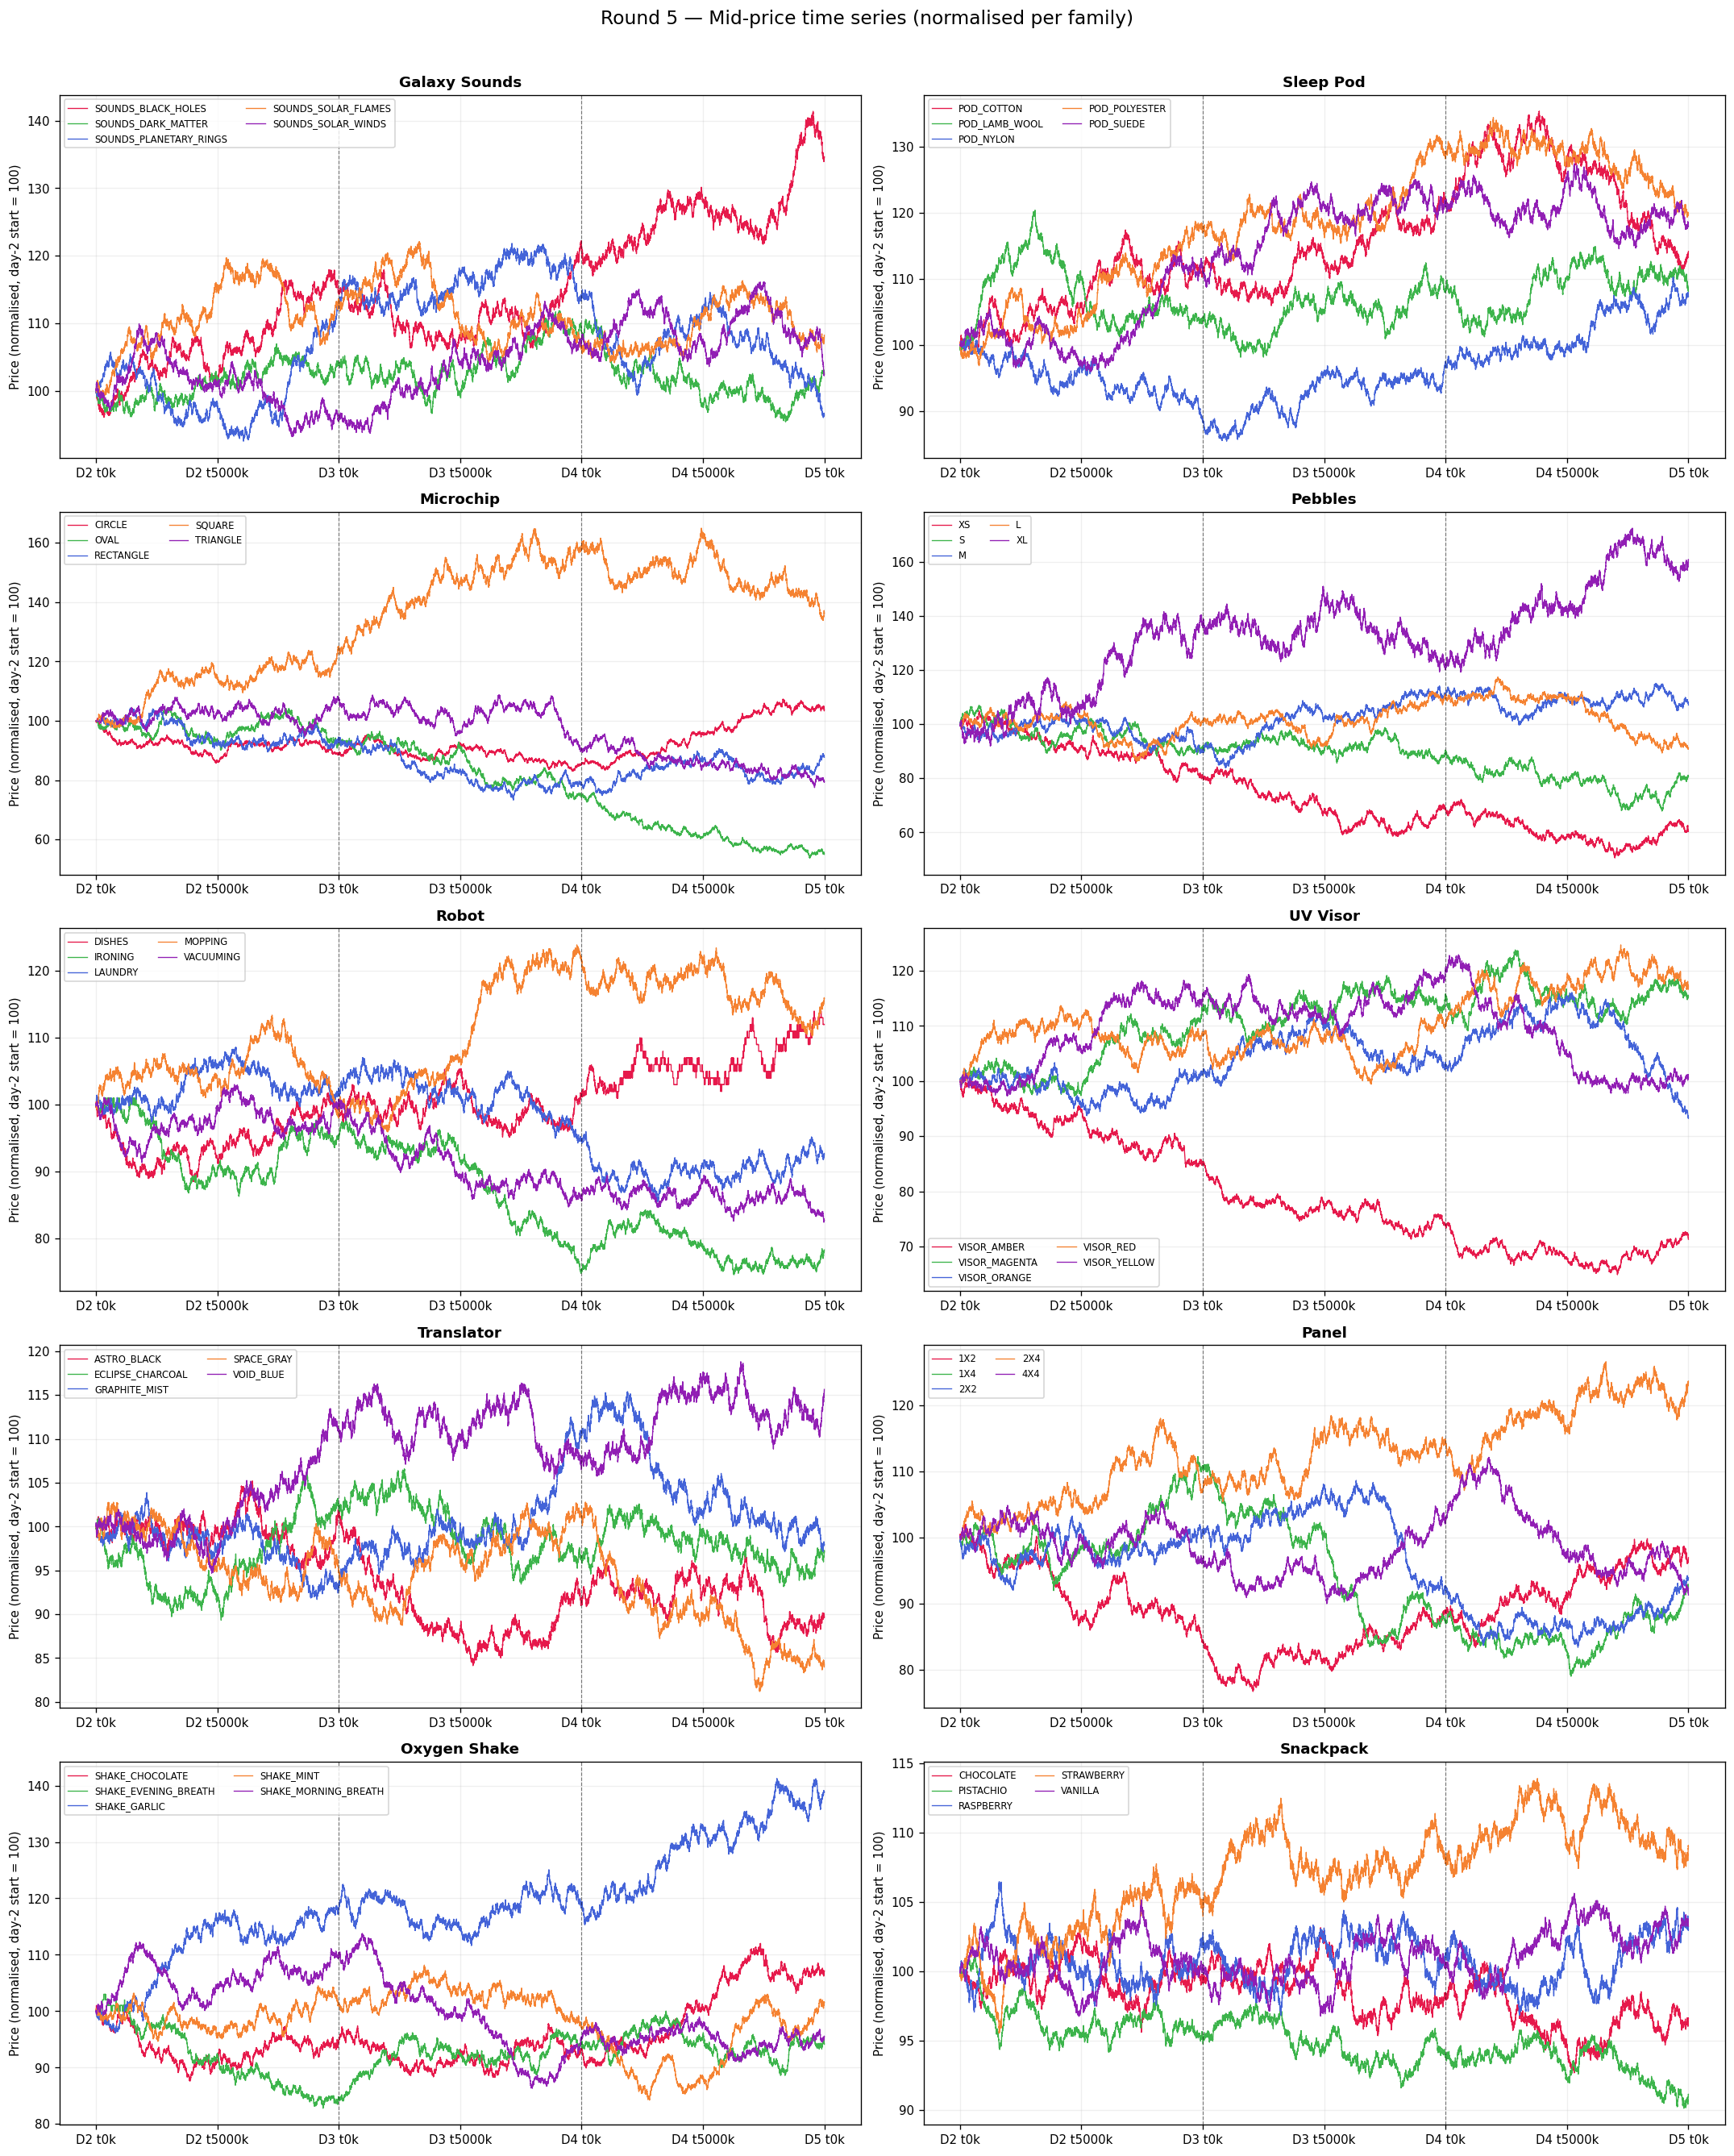

In [3]:
fig, axes = plt.subplots(5, 2, figsize=(18, 22))
axes = axes.flatten()

day_starts = [(d - DAYS[0]) * 1_000_000 for d in DAYS]
COLORS5 = ['#e6194b','#3cb44b','#4363d8','#f58231','#911eb4']

for ax, (fname, prods) in zip(axes, FAMILIES.items()):
    for p, col in zip(prods, COLORS5):
        if p not in mid.columns:
            continue
        series = mid[p].dropna()
        base   = series.iloc[0]
        ax.plot(series.index, series / base * 100, color=col, linewidth=0.8,
                label=p.split('_', 1)[-1])
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
    ax.set_title(fname, fontsize=11, fontweight='bold')
    ax.set_ylabel('Price (normalised, day-2 start = 100)')
    ax.legend(fontsize=7, ncol=2)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))
    ax.grid(True, alpha=0.2)

fig.suptitle('Round 5 — Mid-price time series (normalised per family)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 2 — Correlation matrix (all 50 products)

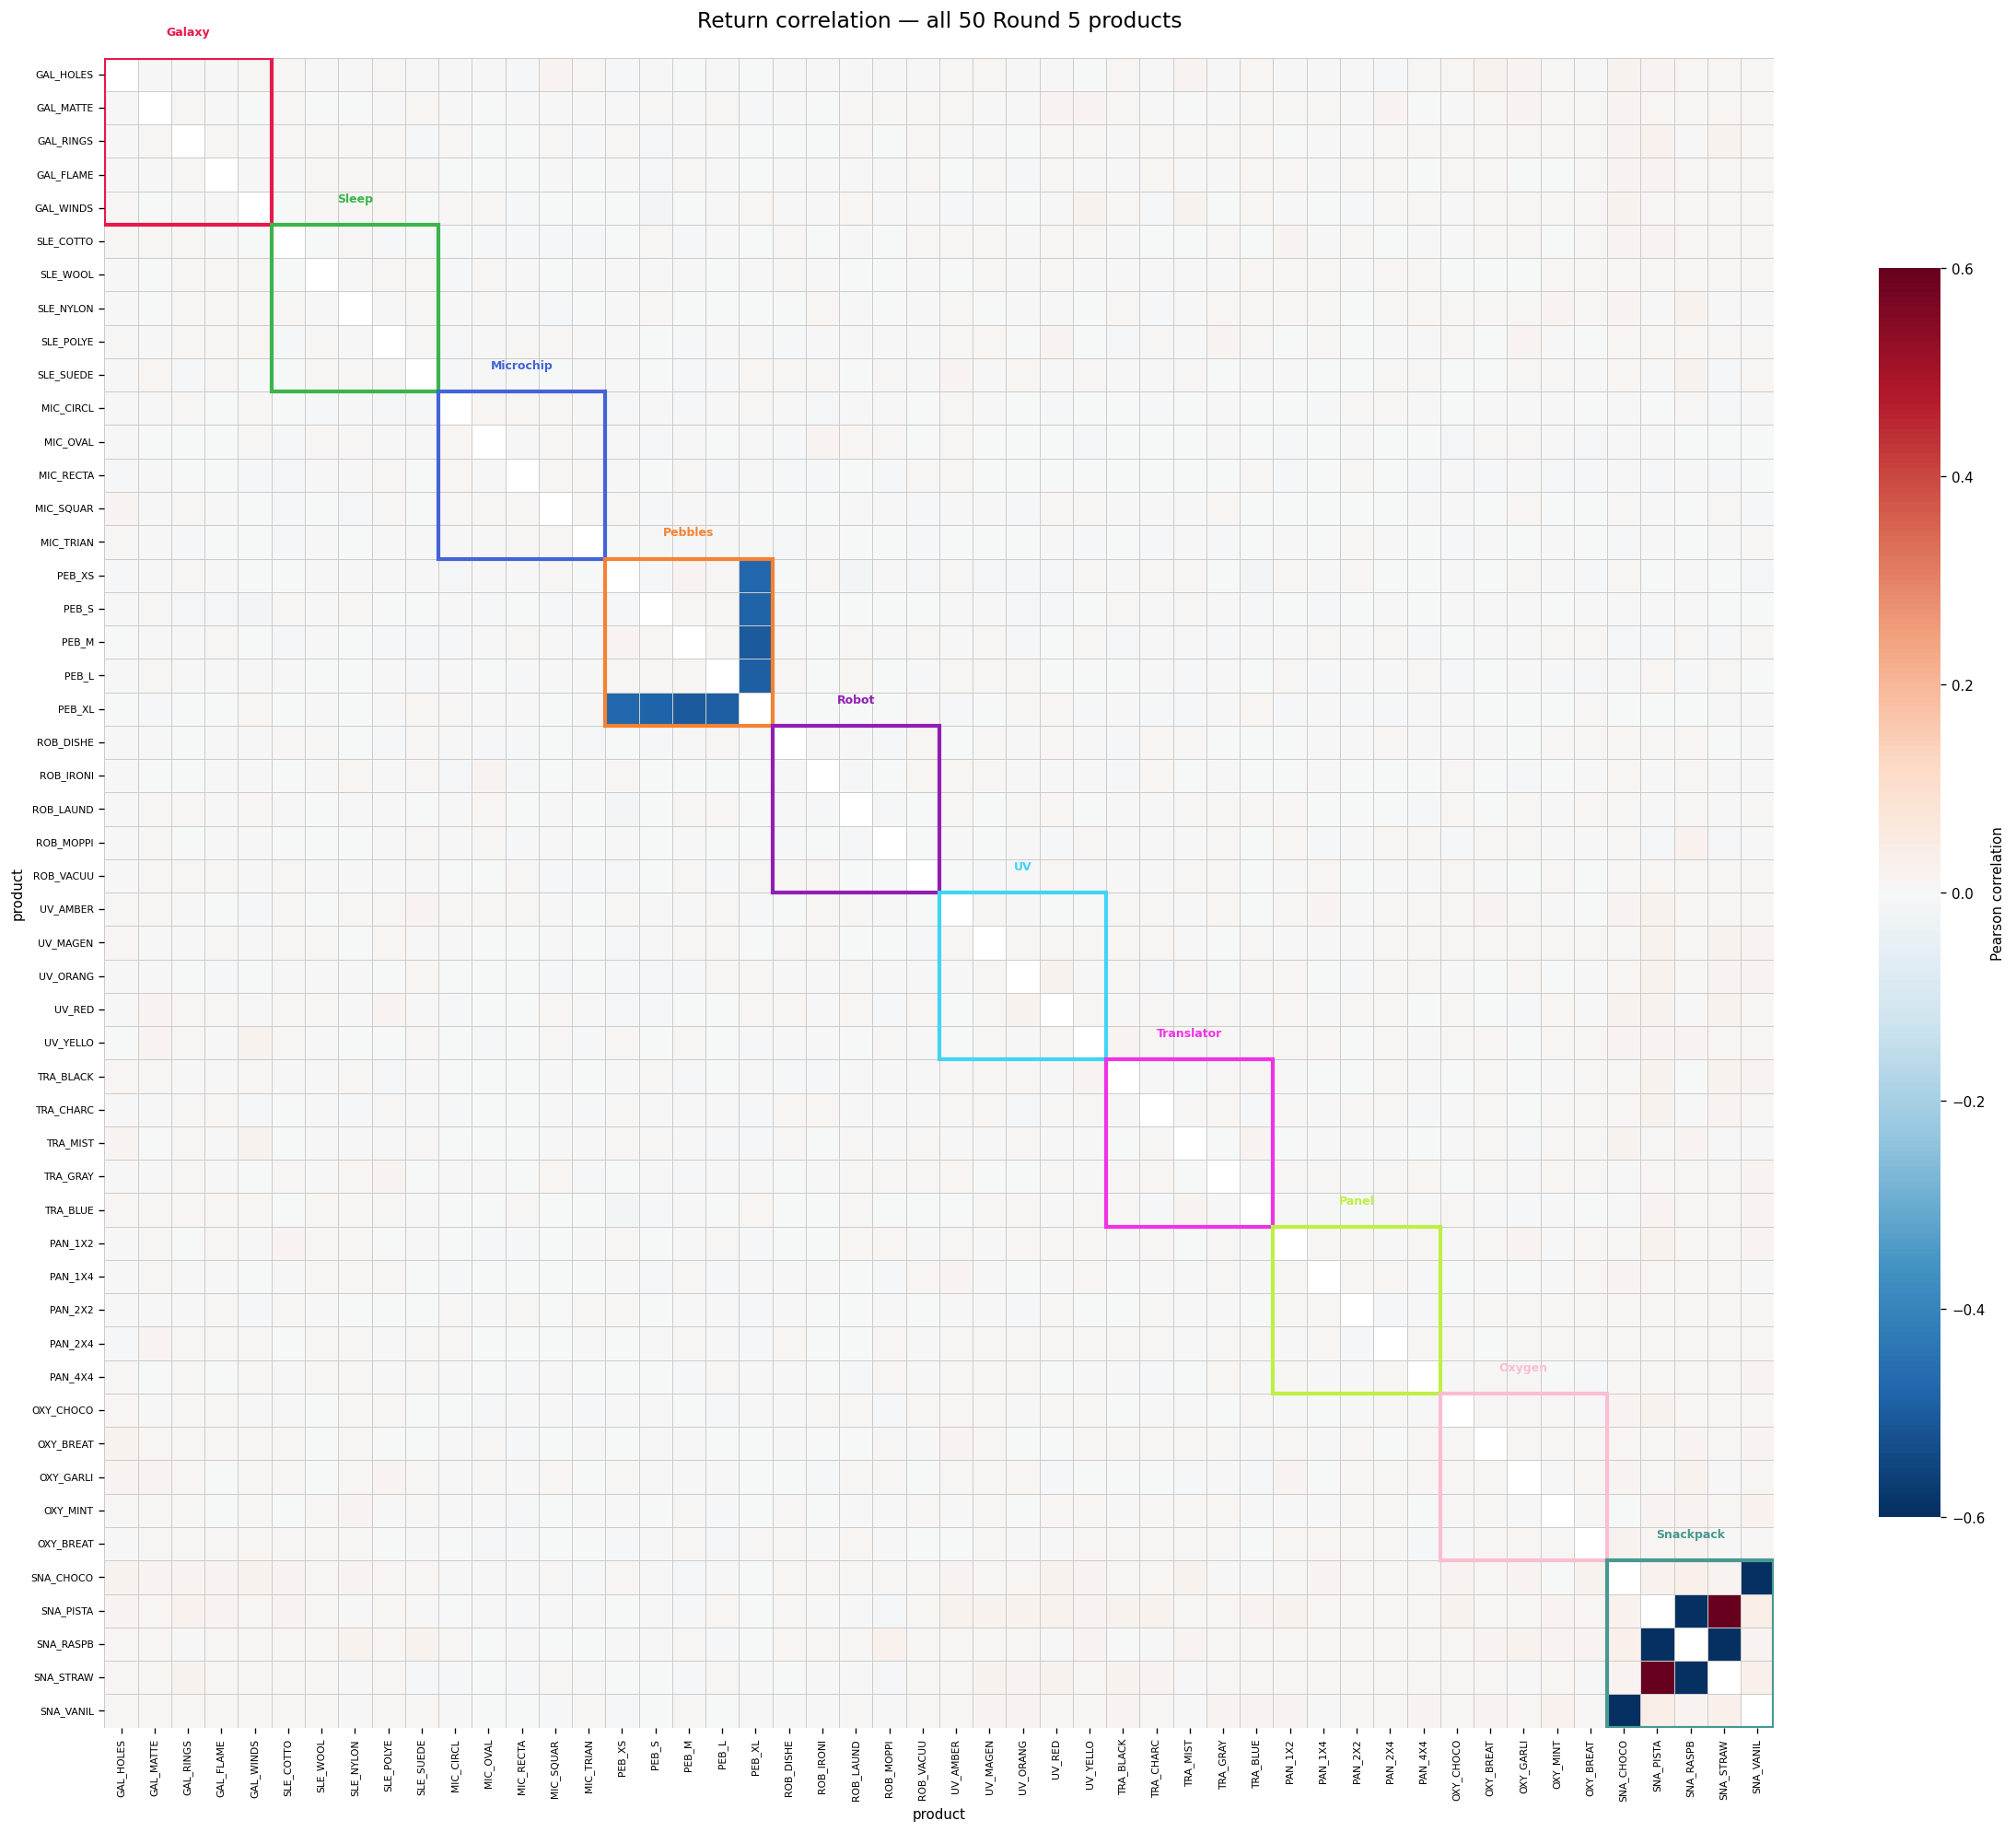

In [4]:
# Use log-returns for correlation (removes level effects)
log_ret = np.log(mid).diff().dropna()

# Reorder columns by family
ordered_cols = [p for prods in FAMILIES.values() for p in prods if p in log_ret.columns]
log_ret_ord  = log_ret[ordered_cols]
corr         = log_ret_ord.corr()

# Family colour bar
row_colors = []
for p in ordered_cols:
    for fname, prods in FAMILIES.items():
        if p in prods:
            row_colors.append(FAM_COLOR[fname])
            break

fig, ax = plt.subplots(figsize=(20, 17))
mask = np.zeros_like(corr, dtype=bool)
np.fill_diagonal(mask, True)

sns.heatmap(
    corr, ax=ax, mask=mask,
    cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6,
    xticklabels=[SHORT.get(p, p) for p in ordered_cols],
    yticklabels=[SHORT.get(p, p) for p in ordered_cols],
    linewidths=0.3, linecolor='#cccccc',
    annot=False, square=True, cbar_kws={'shrink': 0.7, 'label': 'Pearson correlation'}
)

# Draw family group boxes
pos = 0
for fname, prods in FAMILIES.items():
    n = sum(1 for p in prods if p in ordered_cols)
    rect = plt.Rectangle((pos, pos), n, n, fill=False,
                          edgecolor=FAM_COLOR[fname], linewidth=2.5)
    ax.add_patch(rect)
    ax.text(pos + n/2, pos - 0.6, fname.split()[0], ha='center', va='bottom',
            fontsize=7.5, color=FAM_COLOR[fname], fontweight='bold')
    pos += n

ax.set_title('Return correlation — all 50 Round 5 products', fontsize=14, pad=20)
plt.xticks(fontsize=6.5, rotation=90)
plt.yticks(fontsize=6.5, rotation=0)
plt.tight_layout()
plt.show()

## 3 — Intra-family correlation heatmaps

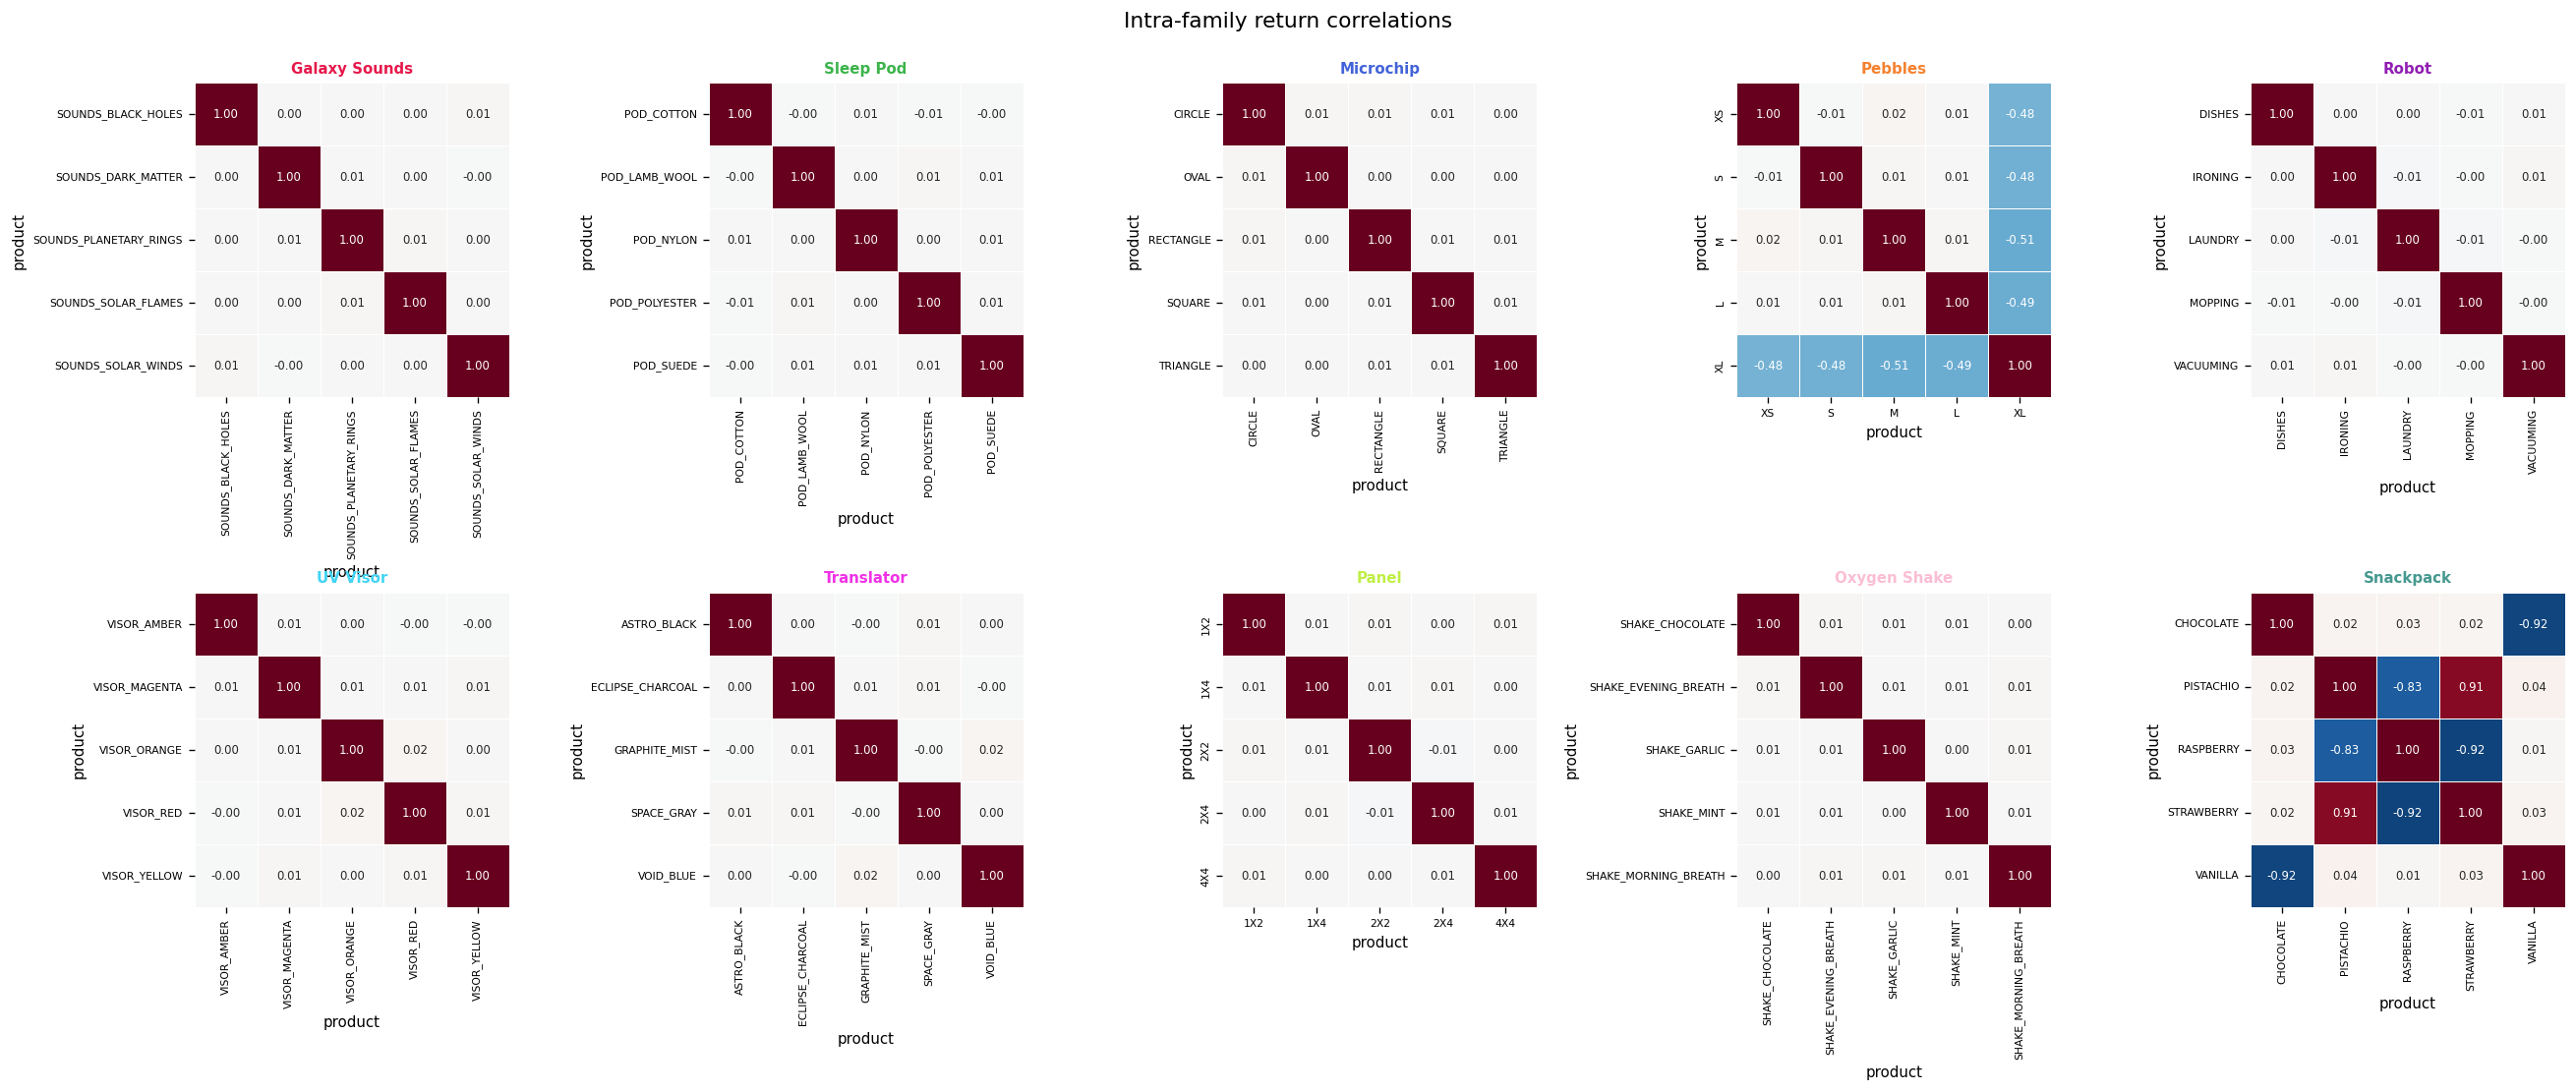

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes = axes.flatten()

for ax, (fname, prods) in zip(axes, FAMILIES.items()):
    avail = [p for p in prods if p in log_ret.columns]
    sub   = log_ret[avail].corr()
    labels = [p.split('_', 1)[-1] for p in avail]
    sns.heatmap(sub, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', square=True,
                xticklabels=labels, yticklabels=labels,
                cbar=False, linewidths=0.5,
                annot_kws={'size': 7})
    ax.set_title(fname, fontsize=9, fontweight='bold',
                 color=FAM_COLOR[fname])
    ax.tick_params(labelsize=6.5)

fig.suptitle('Intra-family return correlations', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 4 — PEBBLES: basket arb
**XS + S + M + L + XL = 50 000 always (std ≈ 2.8).** This is a hard constraint — the strongest signal in the round.

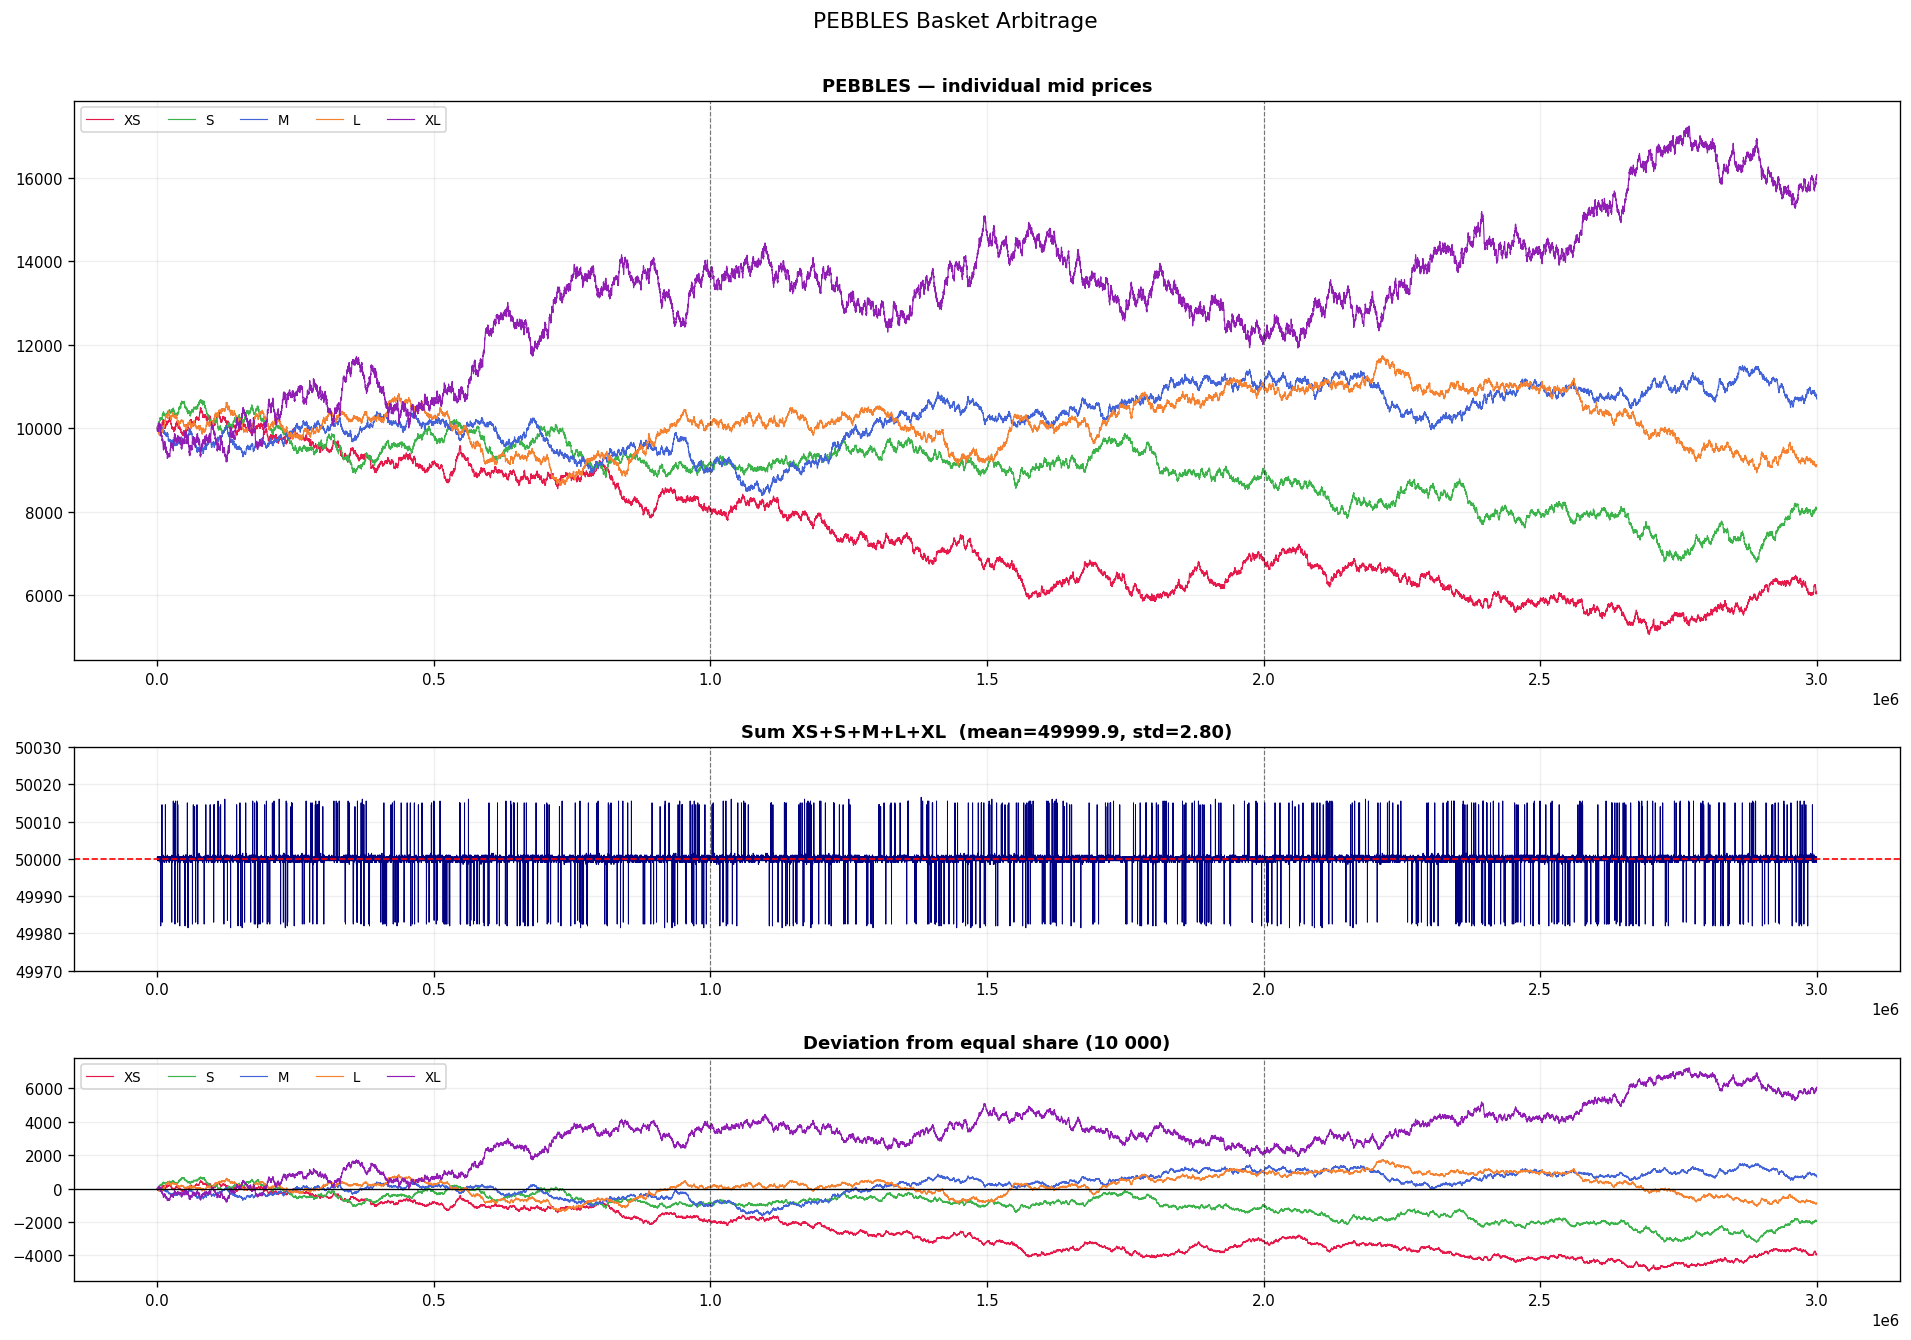

Sum stats: mean=49999.940, std=2.798, min=49982, max=50016
Constraint holds to within 2.8 per tick — near-perfect basket arb.


In [6]:
pebbles = FAMILIES['Pebbles']
peb_mid = mid[pebbles].dropna()
peb_sum = peb_mid.sum(axis=1)

fig, axes = plt.subplots(3, 1, figsize=(16, 11), gridspec_kw={'height_ratios': [2.5, 1, 1]})

# Raw price series
for p, col in zip(pebbles, COLORS5):
    axes[0].plot(peb_mid.index, peb_mid[p], linewidth=0.7, color=col,
                 label=p.split('_')[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
axes[0].set_title('PEBBLES — individual mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

# Basket sum
axes[1].plot(peb_sum.index, peb_sum, color='navy', linewidth=0.6)
axes[1].axhline(50000, color='red', linestyle='--', linewidth=1)
axes[1].set_title(f'Sum XS+S+M+L+XL  (mean={peb_sum.mean():.1f}, std={peb_sum.std():.2f})',
                  fontweight='bold')
axes[1].set_ylim(49970, 50030)
for ds in day_starts[1:]:
    axes[1].axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
axes[1].grid(True, alpha=0.2)

# Deviation from equal share (50000/5 = 10000)
EQUAL_SHARE = 50000 / 5
for p, col in zip(pebbles, COLORS5):
    axes[2].plot(peb_mid.index, peb_mid[p] - EQUAL_SHARE,
                 linewidth=0.7, color=col, label=p.split('_')[-1])
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_title('Deviation from equal share (10 000)', fontweight='bold')
axes[2].legend(ncol=5, fontsize=8)
axes[2].grid(True, alpha=0.2)
for ds in day_starts[1:]:
    axes[2].axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

plt.suptitle('PEBBLES Basket Arbitrage', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print(f'Sum stats: mean={peb_sum.mean():.3f}, std={peb_sum.std():.3f}, '
      f'min={peb_sum.min():.0f}, max={peb_sum.max():.0f}')
print(f'Constraint holds to within {peb_sum.std():.1f} per tick — near-perfect basket arb.')

## 5 — SNACKPACK: stable fair values

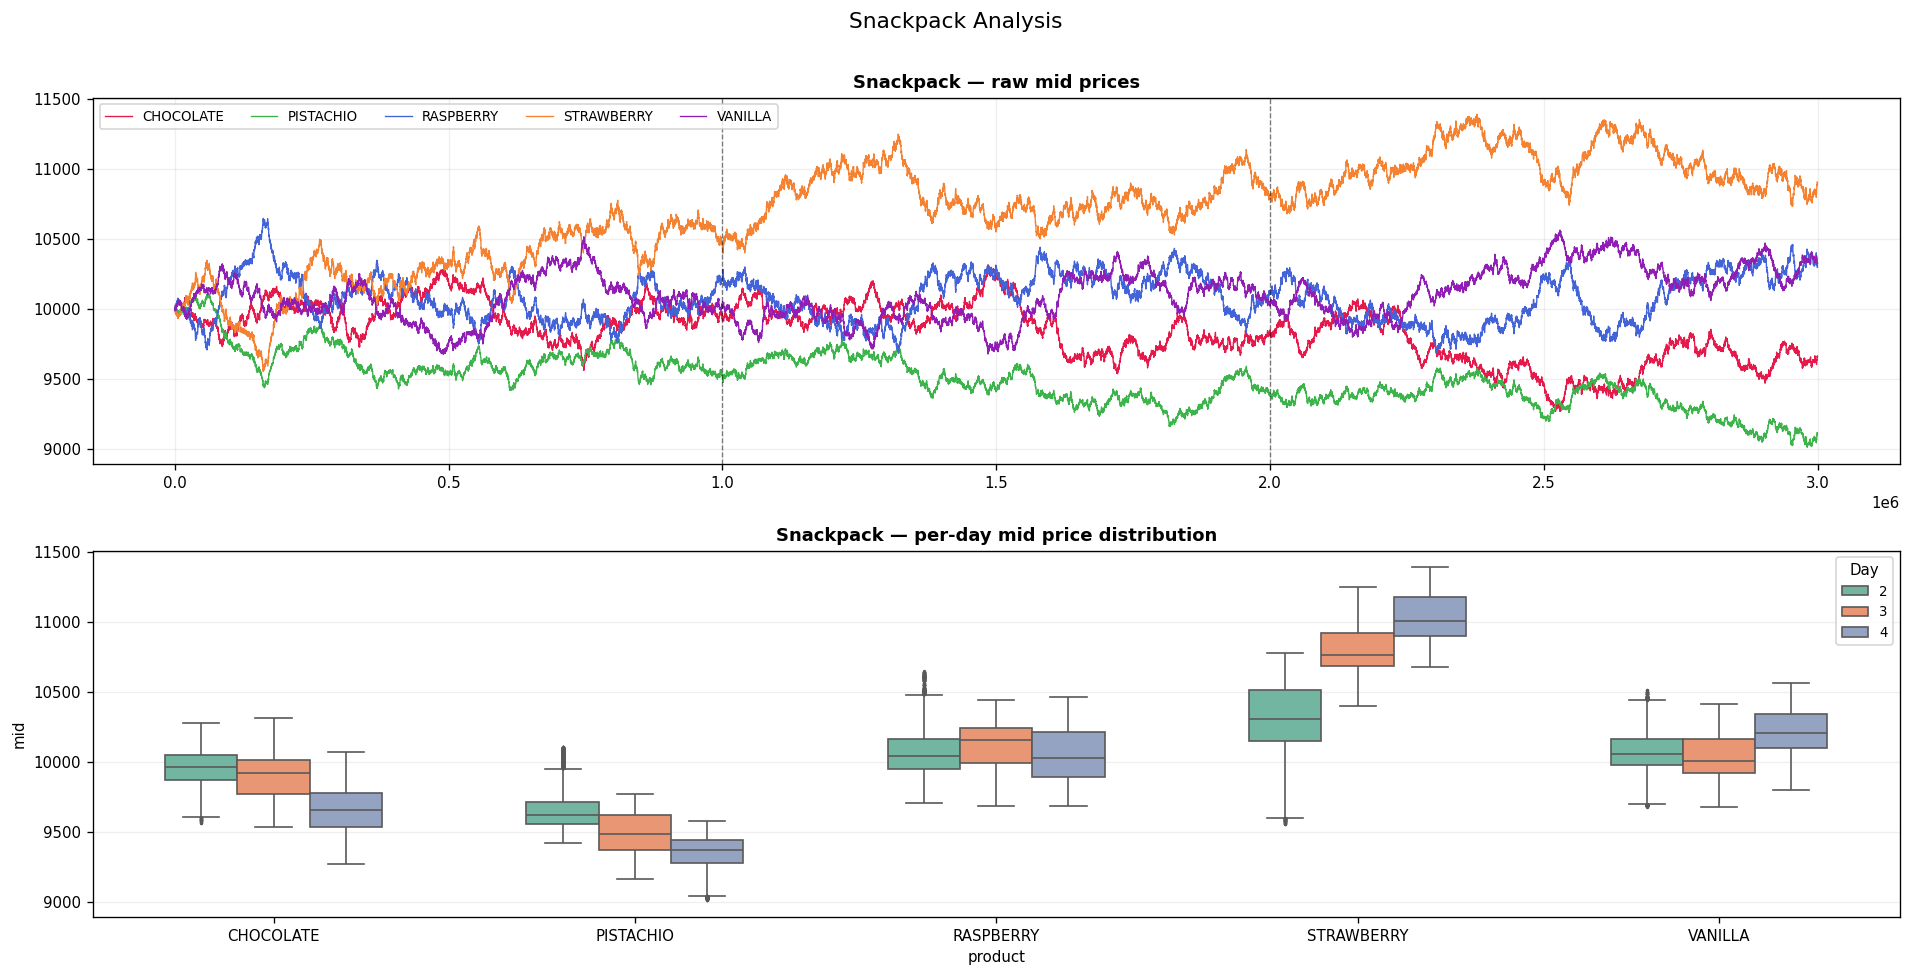


Per-day means:
  CHOCOLATE             d2=9961  d3=9900  d4=9669   range=293   spread=16.5
  PISTACHIO             d2=9656  d3=9487  d4=9345   range=311   spread=15.9
  RASPBERRY             d2=10065  d3=10117  d4=10051   range=66   spread=16.8
  STRAWBERRY            d2=10295  d3=10795  d4=11030   range=735   spread=17.8
  VANILLA               d2=10064  d3=10027  d4=10202   range=175   spread=16.9


In [7]:
snacks = FAMILIES['Snackpack']

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# Time series
for p, col in zip(snacks, COLORS5):
    s = mid[p].dropna()
    axes[0].plot(s.index, s, linewidth=0.8, color=col, label=p.split('_', 1)[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_title('Snackpack — raw mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

# Per-day box plot
snack_by_day = []
for d in DAYS:
    sub = prices[prices['day'] == d]
    for p in snacks:
        vals = sub[sub['product'] == p]['mid_price'].dropna().tolist()
        for v in vals:
            snack_by_day.append({'day': d, 'product': p.split('_',1)[-1], 'mid': v})
sdf = pd.DataFrame(snack_by_day)

import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sns.boxplot(data=sdf, x='product', y='mid', hue='day', ax=axes[1], palette='Set2',
                width=0.6, fliersize=1)
axes[1].set_title('Snackpack — per-day mid price distribution', fontweight='bold')
axes[1].grid(True, alpha=0.2, axis='y')
axes[1].legend(title='Day', fontsize=8)

plt.suptitle('Snackpack Analysis', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# Day-mean stability table
print('\nPer-day means:')
for p in snacks:
    means = [prices[(prices['day']==d) & (prices['product']==p)]['mid_price'].mean() for d in DAYS]
    rng   = max(means) - min(means)
    sp    = prices[prices['product']==p].eval('ask_price_1 - bid_price_1').mean()
    print(f"  {p.split('_',1)[-1]:<20}  " +
          '  '.join(f'd{d}={m:.0f}' for d,m in zip(DAYS,means)) +
          f'   range={rng:.0f}   spread={sp:.1f}')

## 6 — Robot: mean reversion analysis

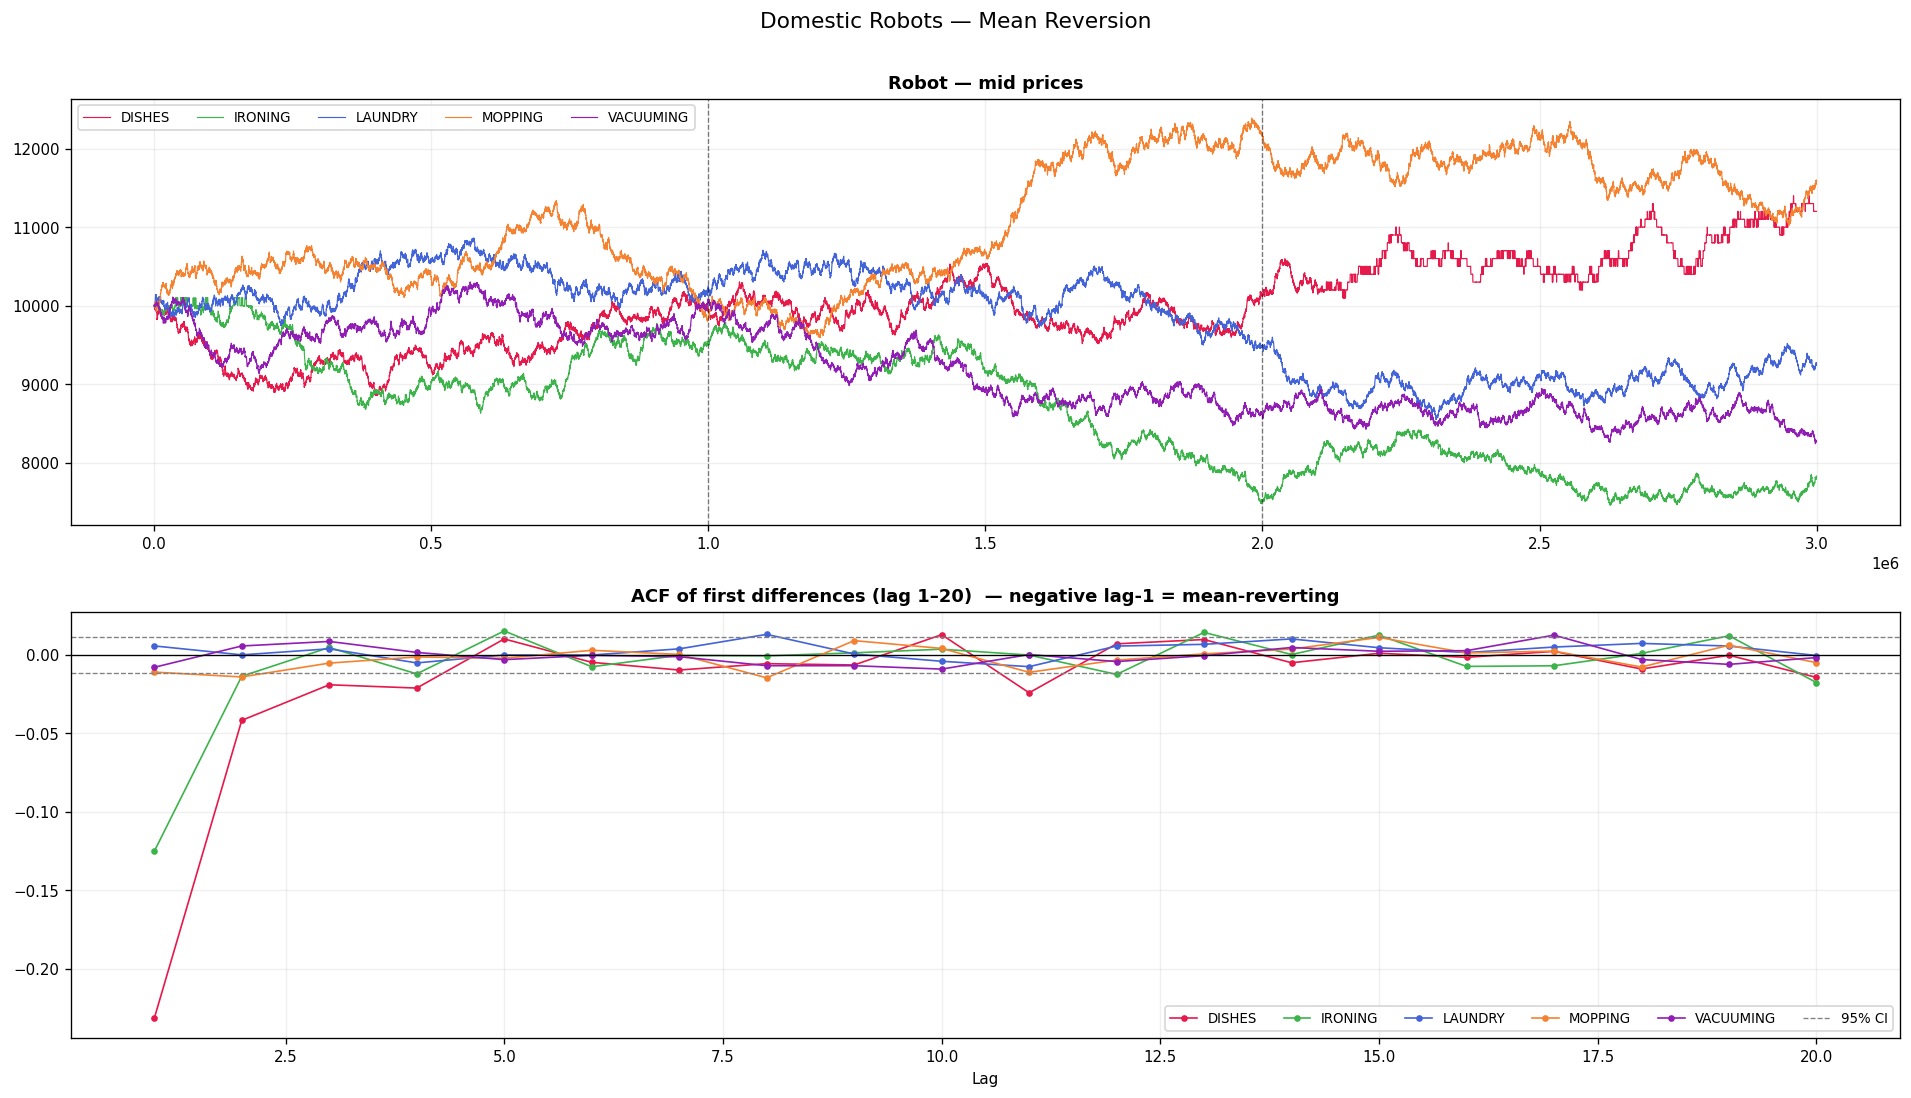


Lag-1 ACF of returns:
  DISHES        ac1=-0.2317   spread=7.4
  IRONING       ac1=-0.1253   spread=6.4
  LAUNDRY       ac1=+0.0057   spread=7.2
  MOPPING       ac1=-0.0110   spread=8.0
  VACUUMING     ac1=-0.0080   spread=6.8


In [8]:
robots = FAMILIES['Robot']

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

for p, col in zip(robots, COLORS5):
    s = mid[p].dropna()
    axes[0].plot(s.index, s, linewidth=0.7, color=col, label=p.split('_',1)[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_title('Robot — mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

# ACF plot (lag 1-20)
from statsmodels.tsa.stattools import acf
MAX_LAG = 20
for p, col in zip(robots, COLORS5):
    s = mid[p].dropna()
    a = acf(s.diff().dropna(), nlags=MAX_LAG, fft=True)
    axes[1].plot(range(1, MAX_LAG+1), a[1:], marker='o', markersize=3,
                 linewidth=1, color=col, label=p.split('_',1)[-1])
axes[1].axhline(0, color='black', linewidth=0.8)
conf = 1.96 / np.sqrt(len(mid))
axes[1].axhline(conf,  color='grey', linestyle='--', linewidth=0.8, label='95% CI')
axes[1].axhline(-conf, color='grey', linestyle='--', linewidth=0.8)
axes[1].set_title('ACF of first differences (lag 1–20)  — negative lag-1 = mean-reverting',
                  fontweight='bold')
axes[1].set_xlabel('Lag')
axes[1].legend(ncol=6, fontsize=8)
axes[1].grid(True, alpha=0.2)

plt.suptitle('Domestic Robots — Mean Reversion', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print('\nLag-1 ACF of returns:')
for p in robots:
    s = mid[p].dropna()
    a = acf(s.diff().dropna(), nlags=1, fft=True)
    sp = prices[prices['product']==p].eval('ask_price_1 - bid_price_1').mean()
    print(f"  {p.split('_',1)[-1]:<12}  ac1={a[1]:+.4f}   spread={sp:.1f}")

## 7 — Oxygen Shake: mean reversion

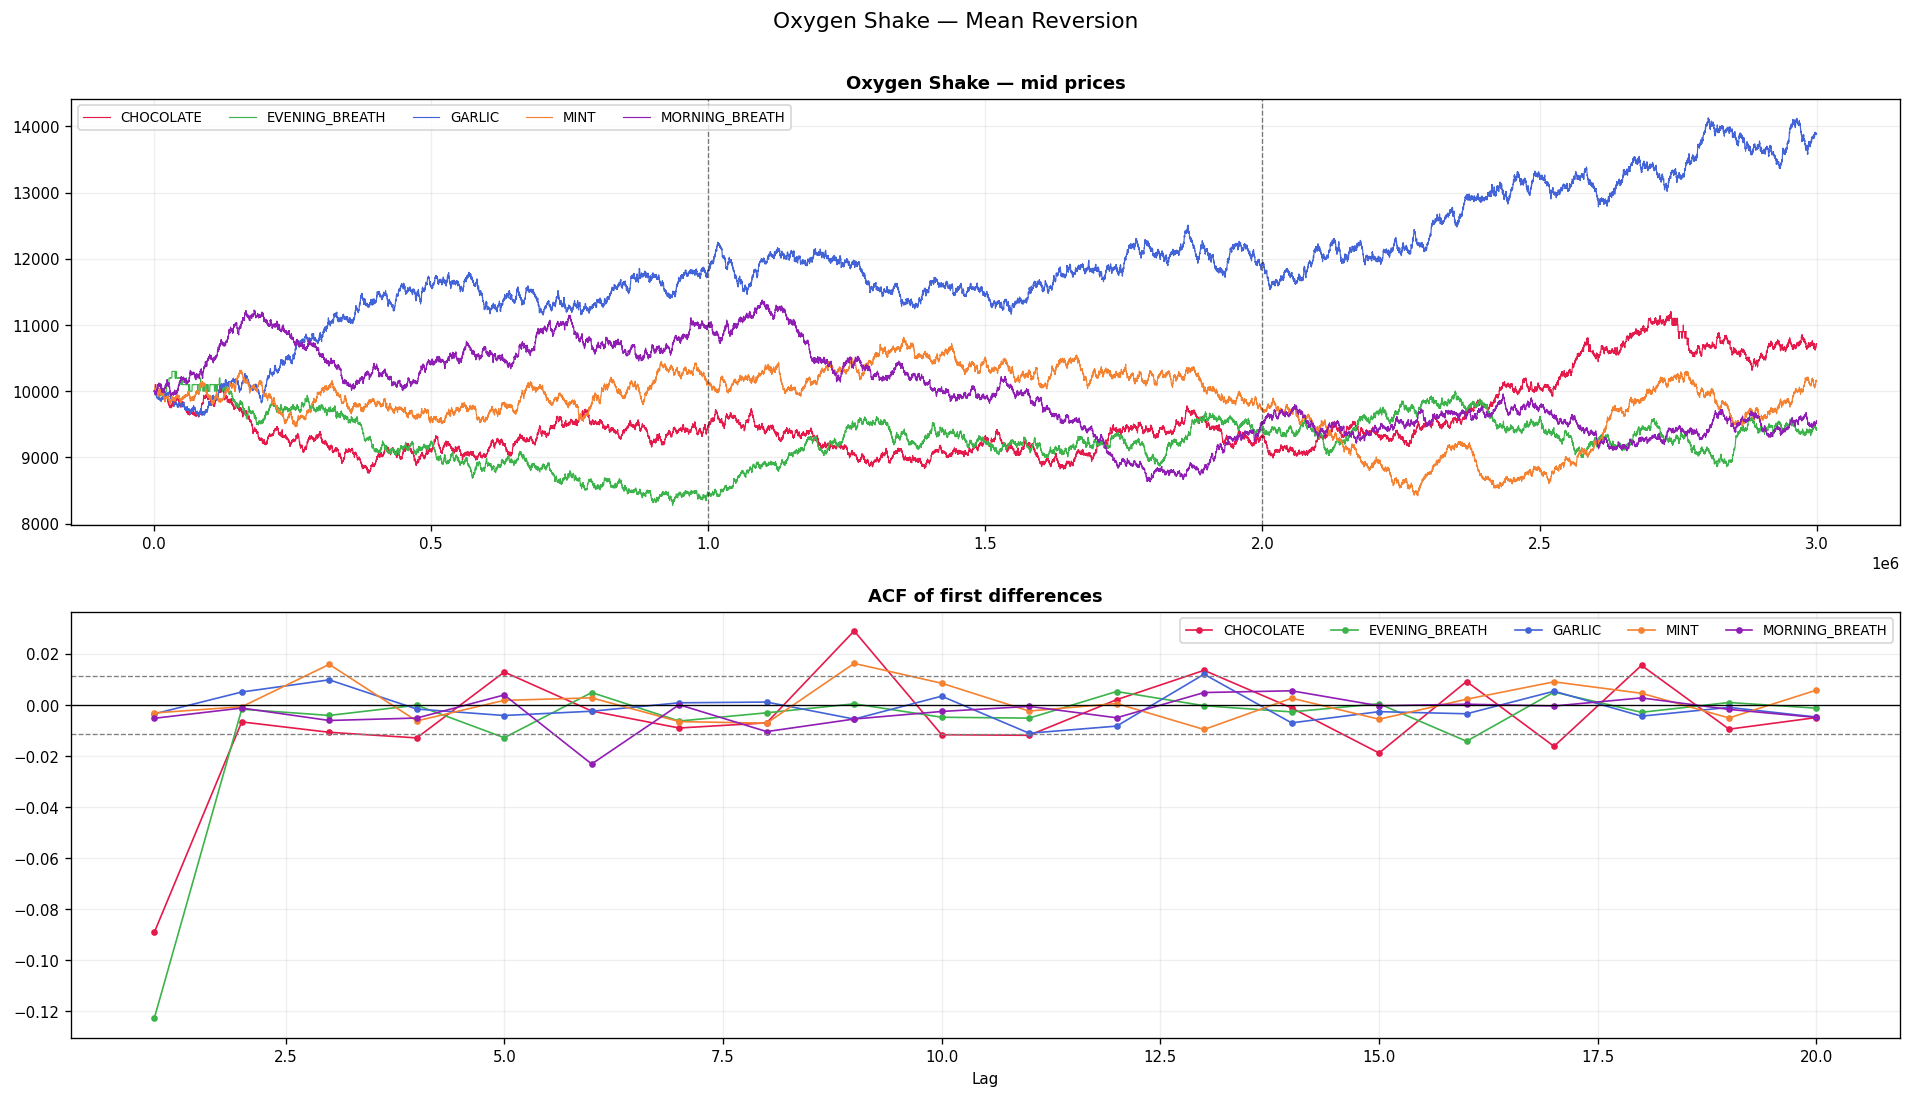

In [9]:
shakes = FAMILIES['Oxygen Shake']

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

for p, col in zip(shakes, COLORS5):
    s = mid[p].dropna()
    axes[0].plot(s.index, s, linewidth=0.7, color=col, label=p.split('_',2)[-1])
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_title('Oxygen Shake — mid prices', fontweight='bold')
axes[0].legend(ncol=5, fontsize=8)
axes[0].grid(True, alpha=0.2)

MAX_LAG = 20
for p, col in zip(shakes, COLORS5):
    s = mid[p].dropna()
    a = acf(s.diff().dropna(), nlags=MAX_LAG, fft=True)
    axes[1].plot(range(1, MAX_LAG+1), a[1:], marker='o', markersize=3,
                 linewidth=1, color=col, label=p.split('_',2)[-1])
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].axhline(conf,  color='grey', linestyle='--', linewidth=0.8)
axes[1].axhline(-conf, color='grey', linestyle='--', linewidth=0.8)
axes[1].set_title('ACF of first differences', fontweight='bold')
axes[1].set_xlabel('Lag')
axes[1].legend(ncol=5, fontsize=8)
axes[1].grid(True, alpha=0.2)

plt.suptitle('Oxygen Shake — Mean Reversion', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 8 — Trending products

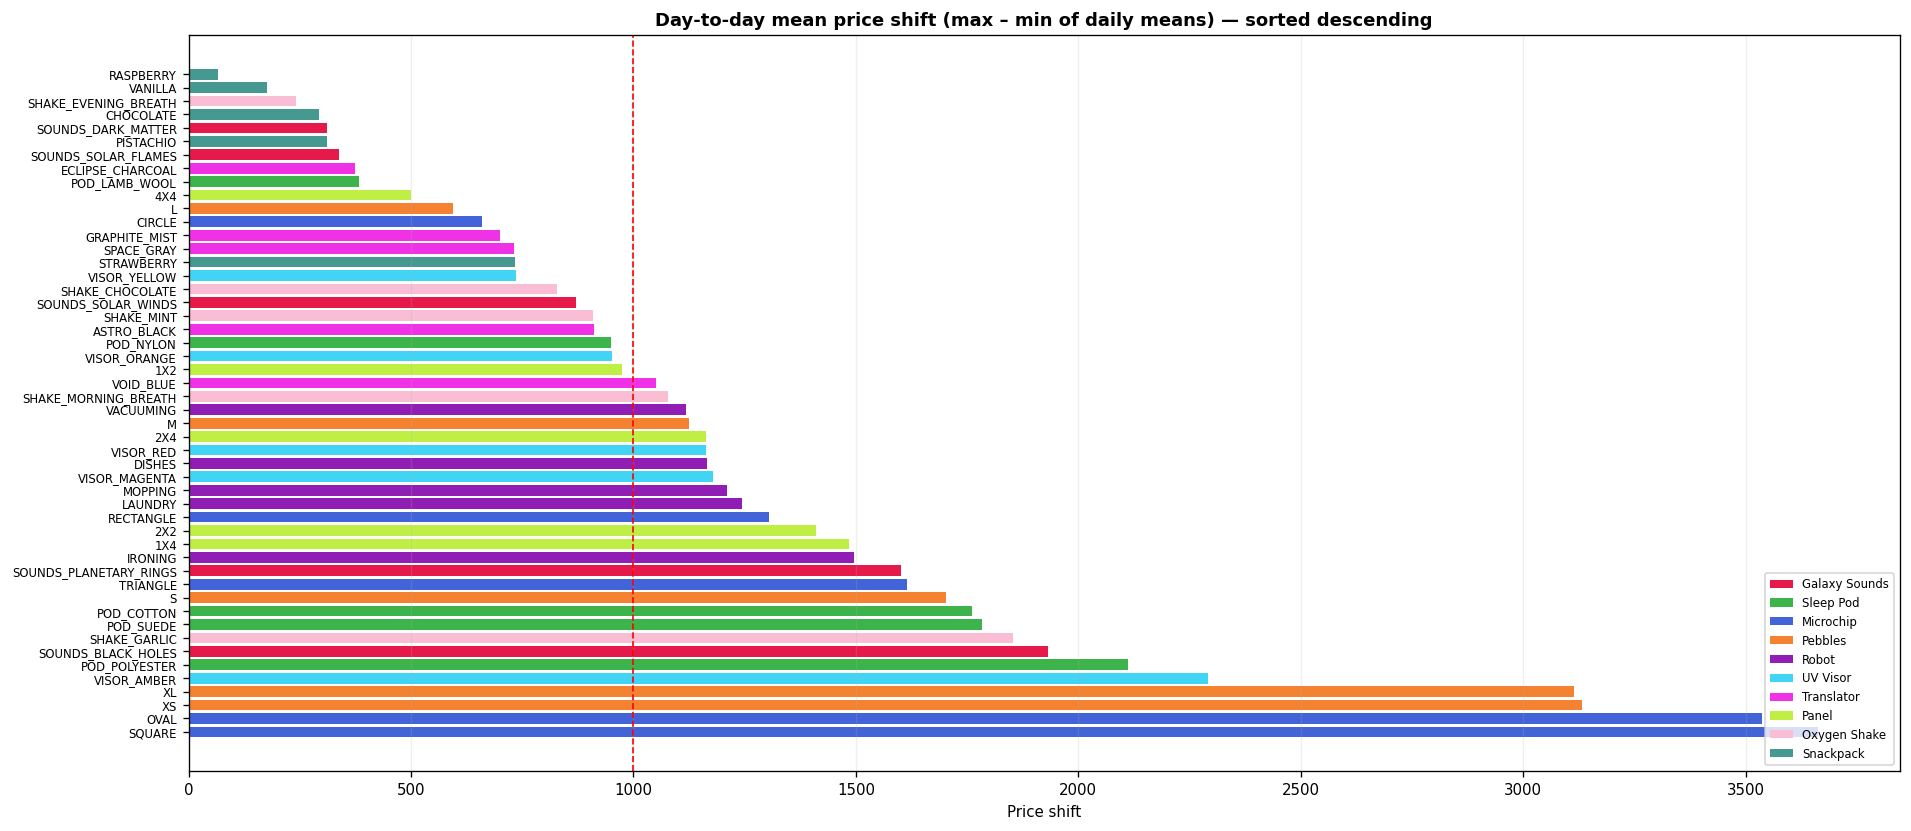


Products with day-shift > 1000 (static FV dangerous):
  MICROCHIP_SQUARE                              3663
  MICROCHIP_OVAL                                3538
  PEBBLES_XS                                    3133
  PEBBLES_XL                                    3115
  UV_VISOR_AMBER                                2292
  SLEEP_POD_POLYESTER                           2113
  GALAXY_SOUNDS_BLACK_HOLES                     1932
  OXYGEN_SHAKE_GARLIC                           1853
  SLEEP_POD_SUEDE                               1783
  SLEEP_POD_COTTON                              1760
  PEBBLES_S                                     1701
  MICROCHIP_TRIANGLE                            1615
  GALAXY_SOUNDS_PLANETARY_RINGS                 1602
  ROBOT_IRONING                                 1496
  PANEL_1X4                                     1485
  PANEL_2X2                                     1411
  MICROCHIP_RECTANGLE                           1304
  ROBOT_LAUNDRY                             

In [10]:
# Compute day-to-day mean shift for all products
shifts = {}
for p in prices['product'].unique():
    d_means = [prices[(prices['day']==d) & (prices['product']==p)]['mid_price'].mean()
               for d in DAYS]
    shifts[p] = max(d_means) - min(d_means)
shift_series = pd.Series(shifts).sort_values(ascending=False)

# Colour by family
prod_to_fam = {p: f for f, prods in FAMILIES.items() for p in prods}
bar_colors  = [FAM_COLOR.get(prod_to_fam.get(p, ''), '#888888') for p in shift_series.index]

fig, ax = plt.subplots(figsize=(16, 7))
ax.barh(range(len(shift_series)), shift_series.values, color=bar_colors)
ax.set_yticks(range(len(shift_series)))
ax.set_yticklabels([p.split('_',1)[-1] for p in shift_series.index], fontsize=7)
ax.axvline(1000, color='red', linestyle='--', linewidth=1, label='1000 threshold')
ax.set_title('Day-to-day mean price shift (max – min of daily means) — sorted descending',
             fontweight='bold')
ax.set_xlabel('Price shift')
ax.grid(True, alpha=0.2, axis='x')

# Legend patches
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=FAM_COLOR[f], label=f) for f in FAMILIES]
ax.legend(handles=legend_elements, fontsize=7, loc='lower right')
ax.legend(handles=legend_elements, fontsize=7, loc='lower right')

plt.tight_layout()
plt.show()

print(f'\nProducts with day-shift > 1000 (static FV dangerous):')
for p, v in shift_series[shift_series > 1000].items():
    print(f'  {p:<45} {v:.0f}')

## 9 — Spread vs volatility (MM profitability map)

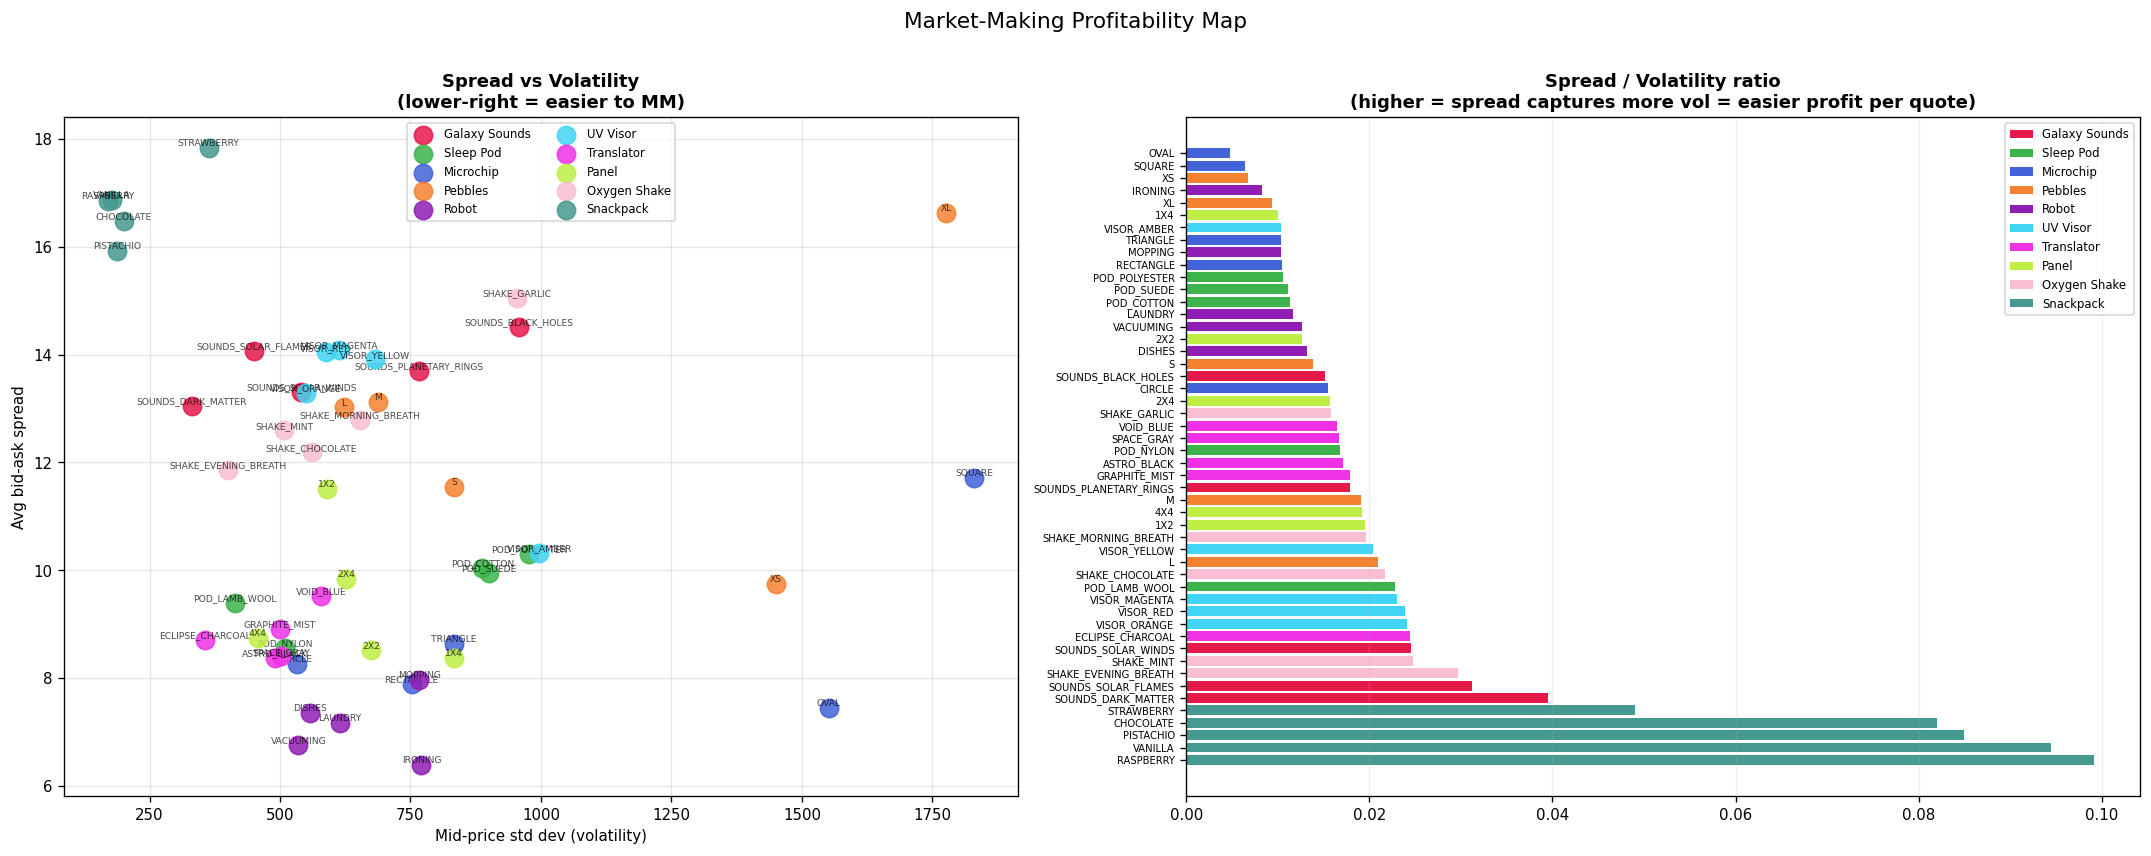


Top-10 MM targets (spread/vol):
                    product    spread        vol  sp_over_vol       ac1
        SNACKPACK_RASPBERRY 16.842467 169.813848     0.099182 -0.016977
          SNACKPACK_VANILLA 16.868667 178.514627     0.094495 -0.026993
        SNACKPACK_PISTACHIO 15.925633 187.495035     0.084939 -0.025015
        SNACKPACK_CHOCOLATE 16.471167 200.733326     0.082055 -0.030963
       SNACKPACK_STRAWBERRY 17.826467 363.573111     0.049031 -0.013691
  GALAXY_SOUNDS_DARK_MATTER 13.050833 330.700516     0.039464 -0.011554
 GALAXY_SOUNDS_SOLAR_FLAMES 14.071533 450.150431     0.031260 -0.011994
OXYGEN_SHAKE_EVENING_BREATH 11.860467 399.821495     0.029664 -0.117962
          OXYGEN_SHAKE_MINT 12.593567 508.131123     0.024784 -0.003201
  GALAXY_SOUNDS_SOLAR_WINDS 13.301267 541.110756     0.024581 -0.007278


In [11]:
records = []
for p in prices['product'].unique():
    sub = prices[prices['product'] == p]
    sp  = (sub['ask_price_1'] - sub['bid_price_1']).mean()
    mids = sub['mid_price'].dropna()
    vol  = mids.std()
    ac1_val = 0.0
    if p in log_ret.columns:
        diff = log_ret[p].dropna()
        if len(diff) > 2:
            ac1_val = diff.autocorr(lag=1)
    fam  = prod_to_fam.get(p, 'Unknown')
    records.append({'product': p, 'family': fam,
                    'spread': sp, 'vol': vol,
                    'sp_over_vol': sp / vol if vol > 0 else 0,
                    'ac1': ac1_val})

rdf = pd.DataFrame(records).sort_values('sp_over_vol', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Scatter: vol vs spread, sized by |ac1|
for fname, prods in FAMILIES.items():
    sub = rdf[rdf['family'] == fname]
    axes[0].scatter(sub['vol'], sub['spread'], s=120, color=FAM_COLOR[fname],
                    label=fname, zorder=3, alpha=0.85)
    for _, row in sub.iterrows():
        axes[0].annotate(row['product'].split('_',1)[-1],
                         (row['vol'], row['spread']),
                         fontsize=5.5, ha='center', va='bottom', alpha=0.7)
axes[0].set_xlabel('Mid-price std dev (volatility)')
axes[0].set_ylabel('Avg bid-ask spread')
axes[0].set_title('Spread vs Volatility\n(lower-right = easier to MM)', fontweight='bold')
axes[0].legend(fontsize=7, ncol=2)
axes[0].grid(True, alpha=0.3)

# Bar: spread/vol ratio — lower is better for MM
bar_c = [FAM_COLOR.get(prod_to_fam.get(p,''),'#888') for p in rdf['product']]
axes[1].barh(range(len(rdf)), rdf['sp_over_vol'], color=bar_c)
axes[1].set_yticks(range(len(rdf)))
axes[1].set_yticklabels([p.split('_',1)[-1] for p in rdf['product']], fontsize=6)
axes[1].set_title('Spread / Volatility ratio\n(higher = spread captures more vol = easier profit per quote)',
                  fontweight='bold')
axes[1].grid(True, alpha=0.2, axis='x')
legend_elements = [Patch(facecolor=FAM_COLOR[f], label=f) for f in FAMILIES]
axes[1].legend(handles=legend_elements, fontsize=7)

plt.suptitle('Market-Making Profitability Map', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print('\nTop-10 MM targets (spread/vol):')
print(rdf[['product','spread','vol','sp_over_vol','ac1']].head(10).to_string(index=False))

## 10 — Summary stats table (all 50 products)

In [12]:
summary_rows = []
for p in prices['product'].unique():
    sub   = prices[prices['product'] == p]
    mids  = sub['mid_price'].dropna()
    sp    = (sub['ask_price_1'] - sub['bid_price_1']).mean()
    d_means = [prices[(prices['day']==d) & (prices['product']==p)]['mid_price'].mean()
               for d in DAYS]
    dr    = max(d_means) - min(d_means)
    ac1_v = log_ret[p].dropna().autocorr(lag=1) if p in log_ret.columns else np.nan
    fam   = prod_to_fam.get(p, '')
    summary_rows.append({
        'Family': fam,
        'Product': p.split('_', 1)[-1],
        'Mean': round(mids.mean(), 0),
        'Std':  round(mids.std(),  0),
        'Spread': round(sp, 1),
        'Sp/Vol': round(sp / mids.std(), 4),
        'DayRange': round(dr, 0),
        'AC1':  round(ac1_v, 4) if pd.notna(ac1_v) else np.nan,
        'Signal': ('BASKET ARB' if fam == 'Pebbles'
                   else 'STRONG MR' if (pd.notna(ac1_v) and ac1_v < -0.10)
                   else 'mild MR'   if (pd.notna(ac1_v) and ac1_v < -0.03)
                   else 'TRENDING'  if dr > 1500
                   else 'neutral'),
    })

sdf = (pd.DataFrame(summary_rows)
         .sort_values(['Family','Product'])
         .reset_index(drop=True))

def colour_signal(val):
    c = {'BASKET ARB':'background-color:#d4edda',
         'STRONG MR': 'background-color:#cce5ff',
         'mild MR':   'background-color:#e8f4fd',
         'TRENDING':  'background-color:#fff3cd',
         'neutral':   ''}.get(val, '')
    return c

styled = (sdf.style
    .applymap(colour_signal, subset=['Signal'])
    .format({'Mean':'{:.0f}', 'Std':'{:.0f}', 'Spread':'{:.1f}',
             'Sp/Vol':'{:.4f}', 'DayRange':'{:.0f}', 'AC1':'{:+.4f}'})
    .set_caption('Round 5 — Product Summary (all 50)')
)
styled

/var/folders/m1/r509ltd163s9j5gyx98z2mkr0000gn/T/ipykernel_11956/2857432235.py:40: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(colour_signal, subset=['Signal'])


,Family,Product,Mean,Std,Spread,Sp/Vol,DayRange,AC1,Signal
0,Galaxy Sounds,SOUNDS_BLACK_HOLES,11467,958,14.5,0.0151,1932,-0.0167,TRENDING
1,Galaxy Sounds,SOUNDS_DARK_MATTER,10227,331,13.1,0.0395,310,-0.0116,neutral
2,Galaxy Sounds,SOUNDS_PLANETARY_RINGS,10767,766,13.7,0.0179,1602,-0.0031,TRENDING
3,Galaxy Sounds,SOUNDS_SOLAR_FLAMES,11093,450,14.1,0.0313,338,-0.0120,neutral
4,Galaxy Sounds,SOUNDS_SOLAR_WINDS,10438,541,13.3,0.0246,870,-0.0073,neutral
5,Microchip,CIRCLE,9215,533,8.3,0.0155,659,-0.0050,neutral
6,Microchip,OVAL,8180,1552,7.4,0.0048,3538,-0.0074,TRENDING
7,Microchip,RECTANGLE,8732,752,7.9,0.0105,1304,-0.0025,neutral
8,Microchip,SQUARE,13595,1830,11.7,0.0064,3663,-0.0220,TRENDING
9,Microchip,TRIANGLE,9686,833,8.6,0.0104,1615,-0.0077,TRENDING


## 11 — Family deep-dives: Microchip, UV Visor (trending)

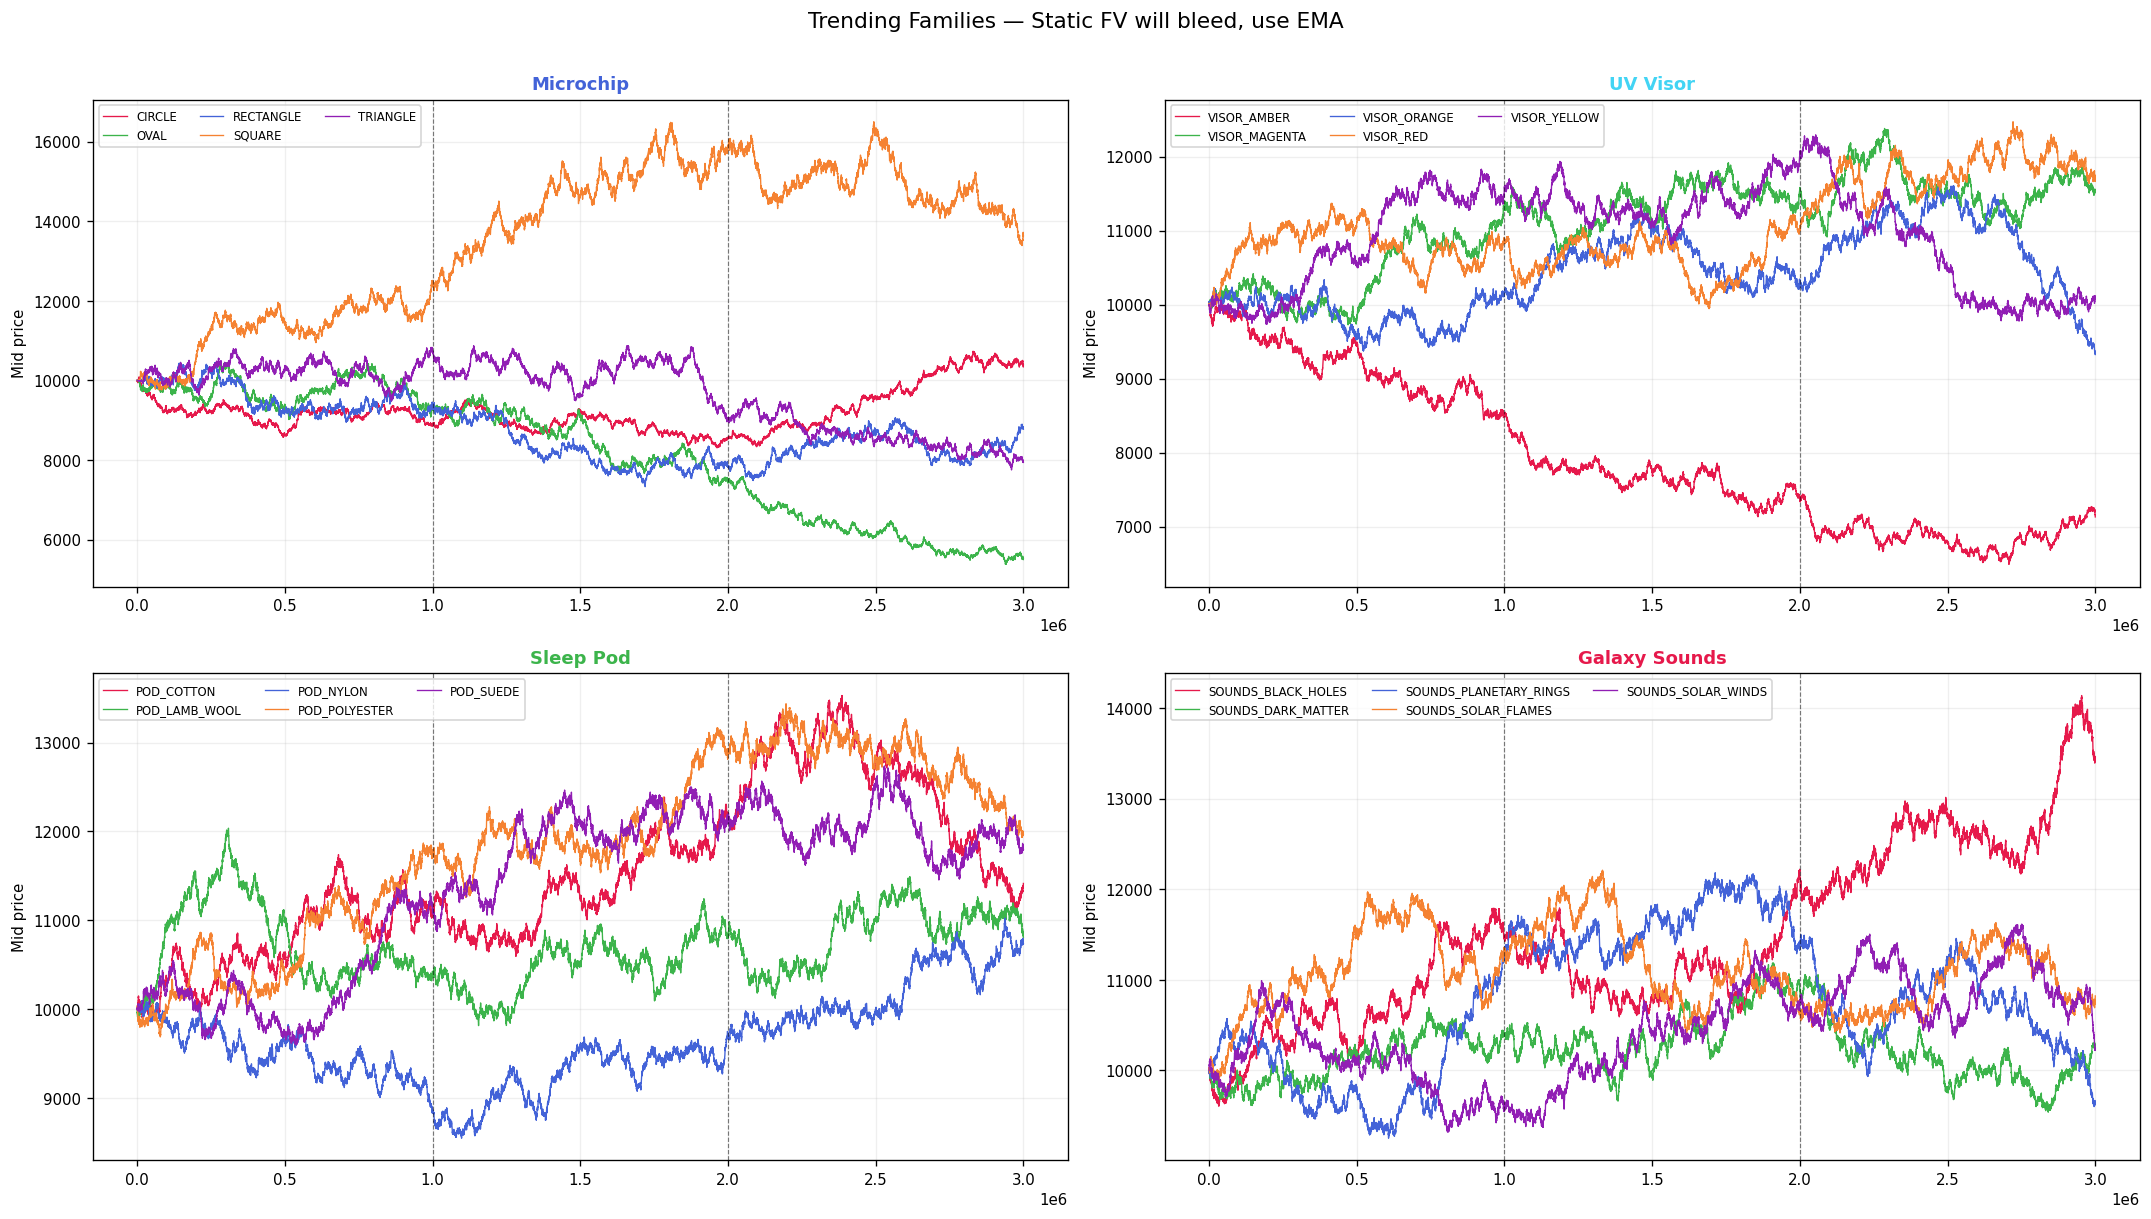

In [13]:
trending_fams = ['Microchip', 'UV Visor', 'Sleep Pod', 'Galaxy Sounds']

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

for ax, fname in zip(axes, trending_fams):
    prods = FAMILIES[fname]
    for p, col in zip(prods, COLORS5):
        if p not in mid.columns: continue
        s = mid[p].dropna()
        ax.plot(s.index, s, linewidth=0.8, color=col, label=p.split('_',1)[-1])
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)
    ax.set_title(fname, fontweight='bold', color=FAM_COLOR[fname])
    ax.legend(ncol=3, fontsize=7)
    ax.grid(True, alpha=0.2)
    ax.set_ylabel('Mid price')

plt.suptitle('Trending Families — Static FV will bleed, use EMA', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 12 — Panel, Translator, UV Visor (remaining families)

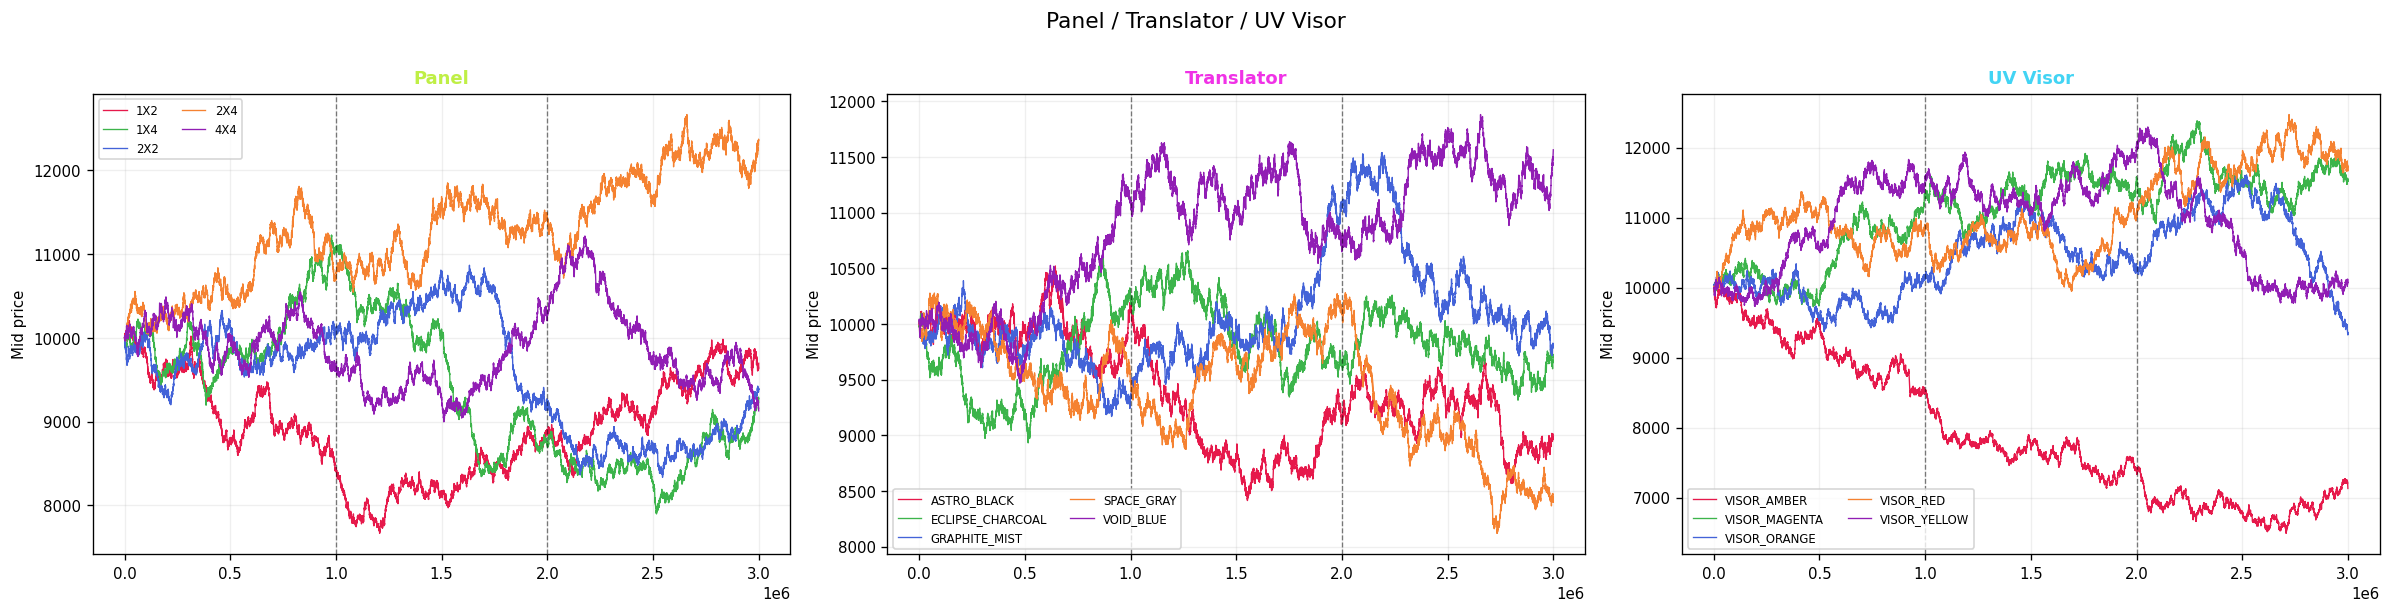

In [14]:
remaining = ['Panel', 'Translator', 'UV Visor']

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, fname in zip(axes, remaining):
    prods = FAMILIES[fname]
    for p, col in zip(prods, COLORS5):
        s = mid[p].dropna()
        ax.plot(s.index, s, linewidth=0.8, color=col, label=p.split('_',1)[-1])
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_title(fname, fontweight='bold', color=FAM_COLOR[fname])
    ax.legend(ncol=2, fontsize=7)
    ax.grid(True, alpha=0.2)
    ax.set_ylabel('Mid price')

plt.suptitle('Panel / Translator / UV Visor', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 13 — Strategy Summary

| Priority | Strategy | Products | Rationale |
|---|---|---|---|
| ★★★★★ | **Basket Arb** | PEBBLES (all 5) | XS+S+M+L+XL = 50 000 always (std=2.8). Hard constraint. Buy underpriced, sell overpriced every tick. |
| ★★★★☆ | **Strong MR** | ROBOT_DISHES, ROBOT_IRONING | ac1 = −0.23, −0.13. Very tight spread (~7). Use MR signal aggressively. Rolling EMA for drifting FV. |
| ★★★★☆ | **Strong MR** | OXYGEN_SHAKE_EVENING_BREATH, CHOCOLATE | ac1 = −0.12, −0.09. Spread ~12. |
| ★★★☆☆ | **MM (stable FV)** | SNACKPACK_RASPBERRY, VANILLA, PISTACHIO | Day-mean range < 175. FVs near-static. Post inside wide spread (~17) to collect premium. |
| ★★★☆☆ | **MM + EMA FV** | ROBOT_MOPPING/VACUUMING/LAUNDRY | Moderate MR. Day-mean drifts → use short EMA for FV anchor. |
| ★★☆☆☆ | **EMA MM** | TRANSLATOR, SLEEP_POD, PANEL | Mild drift, moderate spreads. EMA-blended FV, conservative sizing. |
| ★★☆☆☆ | **Momentum / EMA** | MICROCHIP_SQUARE/OVAL, UV_VISOR_AMBER, PEBBLES_XL/XS | Day shifts > 2000. Static FV bleeds. EMA or momentum signal required. |
| ★★☆☆☆ | **EMA MM** | GALAXY_SOUNDS, OXYGEN_SHAKE_GARLIC | Moderate vol, moderate drift. |

**Position limit = 10 on every product.**  
PEBBLES basket arb requires holding positions in all 5 simultaneously → max exposure = 50 units across the family.  
SNACKPACK: wide spread but slow moves → MM at pos-limit is safe.  
ROBOT_DISHES: fast MR → aggressive MR entry/exit optimal.

**Open questions:**
- Does SNACKPACK sum (cv=0.38%) also offer a weaker basket signal?
- Is there a PEBBLES "fair share" formula (not equal-weight 10 000) that tightens the residual further?
- Do PANEL sizes have a tile-area cost model? (per-area price falls as size grows: not linear)
- Bot activity: only `XIRECS` visible in trades — no directional signal available from bot IDs.